# Proyecto Fundamentos de Redes Neuronales
## Unidad 1: reporte de calidad de datos · Actividad 5: avance del proyecto, modelo base entrenado

# Comprensión del negocio

¿Es posible predecir automáticamente la categoría de un producto de moda a partir de su imagen, con el fin de automatizar y agilizar el proceso de catalogación en una plataforma de e-commerce?

# Objetivo y alcance del proyecto

## Objetivo general:
En este caso buscamos desarrollar un modelo de clasificación de imágenes basado en una red neuronal convolucional CNN, que prediga la categoría de un producto de moda a partir de su imagen, con el fin de automatizar el proceso de catalogación en una plataforma de e-commerce.

## Alcance:

El proyecto se desarrolla en varias etapas en cada una de las unidades. En esta etapa el alcance sería:

- Formular y contextualizar el problema como una pregunta analítica orientada a la toma de decisiones.
- Justificar la pertinencia de una CNN frente a alternativas más simples como modelos lineales, dada la naturaleza espacial de los datos de imagen.
- Evaluar la calidad del dataset "Fashion Product Images (Small)": completitud, duplicados, correspondencia imagen-metadato, consistencia de etiquetas, balance de clases e integridad de las imágenes.

El alcance final del proyecto, a completarse en las etapas siguientes de las unidades, es entrenar, ajustar y evaluar una CNN funcional sobre el conjunto de imágenes ya auditado en esta etapa, aplicando las estrategias de tratamiento de desbalance y estandarización de preprocesamiento que pudimos ver necesarias en este caso, hasta obtener un modelo capaz de clasificar correctamente la categoría del producto.

# Contexto del problema

https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small/data

El comercio electrónico es uno de los sectores que más ha transformado la forma de
consumir, y actualmente sigue en auge, creciendo cada vez más: desde artículos de aseo
personal hasta productos de moda. Empresas como Mercado Libre y Amazon son ejemplos
representativos de este modelo de negocio.

De acuerdo con Robles (2025), en Colombia la venta de artículos de moda se consolidó en
2025 como uno de los sectores de mayor dinamismo dentro del comercio electrónico
colombiano. Este fenómeno no se limita a Colombia: en España, según Modaes (2025), el
sector de la moda superó por primera vez en 2024 el 25% del total de las ventas del
comercio electrónico, ganando cada vez más protagonismo.

Este crecimiento, sin embargo, no ha sido casual. Según Robles (2025), en el caso
colombiano ha sido posible gracias a una mayor sensibilidad hacia la experiencia del
usuario, los tiempos de entrega y sus preferencias. Por su parte, Modaes (2025) señala
que, en España, frente a márgenes de ganancia estrechos y clientes cada vez más
exigentes, la escalabilidad del negocio se convierte en una prioridad, para lo cual es
necesario combinar datos, personalización y tecnología con el fin de maximizar el valor
de cada cliente.

Es por esto que este trabajo no busca quedarse únicamente en el análisis descriptivo del
sector, sino ir más allá, proponiendo una solución que mejore la experiencia tanto de
los compradores como de los vendedores que usan estas plataformas: un sistema automático
capaz de detectar el tipo de prenda a partir de su imagen (por ejemplo, si se trata de
una camisa, un pantalón, etc.).

## Stakeholders

- **Vendedores:** uno de los stakeholders más importantes, ya que la propuesta busca
  que puedan subir sus productos con mayor facilidad, contando con un sistema que les
  ayude a completar automáticamente datos básicos como el tipo de prenda (pantalón,
  camisa, etc.).
- **Compradores:** se benefician de una experiencia de compra más completa, con
  imágenes e información relevante sobre las prendas correctamente clasificadas.
- **Dueños de la plataforma:** buscan aumentar la cantidad de usuarios que utilizan la
  plataforma, tanto para vender como para comprar.

## Referencias

- Modaes. (2025, 27 de junio). *La moda online bate un nuevo récord y supera por primera
  vez el 25% de cuota en España*. Modaes.
  https://www.modaes.com/entorno/la-moda-online-bate-un-nuevo-record-y-supera-por-primera-vez-el-25-de-cuota-en-espana

- Robles, L. (2025, 16 de diciembre). *Moda en Colombia proyecta un crecimiento del 11%
  al cierre de 2025, con el ecommerce liderando el comportamiento del sector*. Publimetro
  Colombia.
  https://www.publimetro.co/estilo-vida/2025/12/16/moda-en-colombia-proyecta-un-crecimiento-del-11-al-cierre-de-2025-con-el-ecommerce-liderando-el-comportamiento-del-sector/

## Objetivos de negocio:

- Reducir el tiempo y esfuerzo que invierten los vendedores al publicar un nuevo producto, automatizando la asignación de categoría.
- Mejorar la consistencia y calidad del catálogo disminuyendo de esta forma errores de clasificación.
- Aumentar la satisfacción y retención de vendedores y compradores al ofrecer un catálogo mejor organizado.
- Apoyar la escalabilidad del negocio permitiendo que la plataforma pueda absorber una mayor cantidad de productos nuevos sin incrementar el trabajo de catalogación que se hace manual.

## Objetivos técnicos:

- Entrenar un modelo de red neuronal convolucional que clasifique imágenes de productos de moda según su categoría.
- Alcanzar un desempeño mínimo objetivo en el conjunto de prueba determinado por distintas métricas cómo por ejemplo accuracy, F1-score, etc.
- Tratar posibles desbalance de clases.
- Estandarizar el preprocesamiento de imágenes, unificando el color etc.


## Información del dataset

Este dataset fue encontrado en Kaggle y se llama "Fashion Product Images (Small)". Cada
fila representa un producto, el cual se conecta con su respectiva imagen a través del
campo `id`, que funciona como llave primaria e identificador único.

Esta base de datos contiene originalmente 44,446 filas y 10 columnas, cómo lo son `id`, `gender`,
`masterCategory`, `subCategory`, `articleType`, `baseColour`, `season`, `year`, `usage`
y `productDisplayName`. De estas, 5 filas no cuentan con su imagen correspondiente en
disco, por lo que fueron descartadas, quedando un total de 44,441 registros válidos
para el análisis. A continuación se presenta el reporte de calidad correspondiente.

La variable objetivo del modelo es `articleType`, ya que representa la categoría específica del producto que se busca predecir automáticamente. Por el desbalance extremo encontrado (142 clases, 52 de ellas con menos de 20 registros), se restringe a las clases con al menos 200 imágenes únicas: 40 clases que cubren el 90.3% del catálogo (la justificación está en la sección *Decisión del nivel de la variable objetivo*).

La variable predictora es la imagen asociada a cada producto (`image_path`), que la CNN recibe como un tensor de 80 (alto) x 60 (ancho) x 3 (canales RGB): cada imagen aporta 14,400 valores de píxel x₁...x₁₄₄₀₀ normalizados en [0, 1]. Las columnas restantes (`gender`, `masterCategory`, `subCategory`, `baseColour`, `season`, `year`, `usage` y `productDisplayName`) son metadatos y no se emplearán como entrada del modelo en esta fase, ya que el alcance del proyecto se centra en la clasificación basada en imagen. La siguiente tabla resume la decisión sobre cada variable.

## Diccionario de variables

| Variable | Rol | Tipo | Dominio | Calidad (hallazgo) | Decisión | Razón |
|---|---|---|---|---|---|---|
| `articleType` | Objetivo (y) | Categórica nominal | 40 clases con >= 200 imágenes | 142 valores originales, desbalance 7,069x | Usar (filtrada) | Nivel de detalle que necesita el vendedor |
| imagen (`image_path`) | Entrada (X) | Numérica: tensor 80x60x3 | x₁...x₁₄₄₀₀ en [0, 1] | 431 en grises, 23 con otra resolución, 779 copias exactas | Usar | Única entrada del modelo; se convierte a RGB y se redimensiona |
| `id` | Identificador | Entero | Único por registro | Sin duplicados | No es entrada | Llave que une imagen y metadatos |
| `gender` | Metadato | Categórica (5) | Men, Women, Unisex, Boys, Girls | Completa | No en esta fase | Candidata para un modelo multimodal: se conoce al publicar y no revela la clase |
| `masterCategory` | Metadato jerárquico | Categórica (7) | Apparel, Accessories, Footwear, ... | `Home` con 1 registro | Excluir como entrada | Es un nivel superior de `articleType`: usarla filtraría la respuesta (fuga); solo para analizar errores |
| `subCategory` | Metadato jerárquico | Categórica (45) | Topwear, Shoes, Bags, ... | Clases con 1 registro | Excluir como entrada | Fuga por jerarquía; solo para analizar errores |
| `baseColour` | Metadato | Categórica (46 + 'NA') | Black, Blue, White, ... | 15 'NA' | No en esta fase | El color ya está en los píxeles; candidata multimodal |
| `season` | Metadato | Categórica (4) | Fall, Spring, Summer, Winter | 21 vacías | Excluir | Relación débil con el tipo de artículo |
| `year` | Metadato | Entero | 2008-2019 | 1 vacía | Excluir | Fecha de catálogo; no describe la apariencia |
| `usage` | Metadato | Categórica (8) | Casual, Sports, Ethnic, ... | 316 'NA' + 1 vacía | Excluir | Ausencias y relación débil con el tipo |
| `productDisplayName` | Texto libre | Texto | Ej.: "Puma Men Grey T-shirt" | 22 filas con comas internas, 7 'NA' | Excluir | Contiene el nombre del tipo de artículo: fuga directa |

## ¿Por qué una red neuronal?

Para este proyecto se trabajará específicamente con una **red neuronal convolucional
(CNN)**. Según explica IBM (2025), este tipo de arquitectura se utiliza ampliamente en
tareas de reconocimiento de voz y de clasificación, siendo esta última precisamente el
tipo de problema que se busca resolver, el cuál es clasificar imágenes de prendas (camisas,
pantalones, zapatos, etc.) según su categoría. Las CNN se distinguen de otras
arquitecturas de red neuronal por su buen desempeño en datos de tipo imagen, voz y
audio, gracias a su capacidad de aprovechar la estructura espacial de los datos.

Esto es precisamente lo que hace inadecuado el uso de un modelo lineal para este
problema ya que un modelo lineal trataría cada píxel de la imagen como una variable
independiente, sin capturar relaciones espaciales entre píxeles vecinos ni ser capaz
de reconocer un mismo patrón en distintas
posiciones de la imagen. Las capas convolucionales de una CNN, en cambio, aprenden
filtros que detectan patrones visuales (bordes, texturas, formas) de manera
independiente a su ubicación exacta, y los combinan progresivamente en representaciones
cada vez más complejas.
Esta capacidad de aprender representaciones jerárquicas y no lineales es la razón
técnica por la cual una CNN resulta más adecuada que un modelo lineal para clasificar
las imágenes del dataset "Fashion Product Images (Small)".

Esta decisión también se sostiene frente a alternativas más fuertes que un modelo lineal:

- **Red densa (MLP) sobre los píxeles aplanados:** es no lineal, pero cada neurona se conecta con los 14,400 valores de la imagen, lo que dispara el número de parámetros y no aprovecha la estructura espacial; mover la prenda unos píxeles produce una entrada completamente distinta para la red (Géron, 2017, cap. 13).
- **Extractor clásico de características** (por ejemplo HOG o histogramas de color con un clasificador): los descriptores se diseñan a mano, mientras que la CNN aprende sus filtros a partir de los datos, lo que ayuda cuando las diferencias entre clases son sutiles (camisa frente a camiseta, sandalia frente a chancla).

Bishop y Bishop (2024, cap. 10) explican esta ventaja a partir de los sesgos inductivos de las capas convolucionales: conectividad local, pesos compartidos (que reducen los parámetros y permiten detectar un patrón en cualquier posición) y organización jerárquica de las representaciones, idea que también desarrolla Aggarwal (2023).

**Referencias**

- Aggarwal, C. C. (2023). *Neural networks and deep learning: A textbook* (2nd ed.). Springer. https://doi.org/10.1007/978-3-031-29642-0
- Bishop, C. M., & Bishop, H. (2024). *Deep learning: Foundations and concepts*. Springer. https://doi.org/10.1007/978-3-031-45468-4
- Géron, A. (2017). *Hands-on machine learning with Scikit-Learn and TensorFlow*. O'Reilly Media.
- ¿Qué son las redes neuronales convolucionales? (2025, 26 de noviembre). IBM.
https://www.ibm.com/mx-es/think/topics/convolutional-neural-networks

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# Descarga del dataset (usa caché si ya está disponible en el entorno)
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
print("Dataset en:", path)

100%|██████████| 565M/565M [00:07<00:00, 80.9MB/s]

Extracting files...


Dataset en: /root/.cache/kagglehub/datasets/paramaggarwal/fashion-product-images-small/versions/1


## Lectura de los datos

Carpeta de imágenes: /root/.cache/kagglehub/datasets/paramaggarwal/fashion-product-images-small/versions/1/myntradataset/images
Cantidad de imágenes: 44441


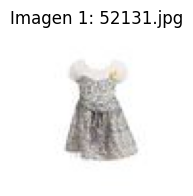

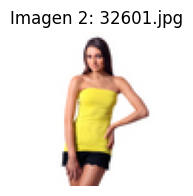

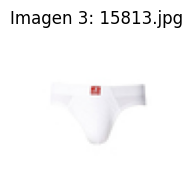

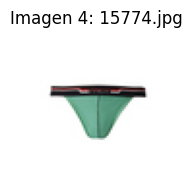

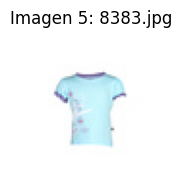

In [ ]:
import matplotlib.image as mpimg
# 1. Definir la ruta de la carpet
ruta_carpeta = os.path.join(
    path,
    "myntradataset",
    "images"
)

# Verificar que la carpeta exista
if not os.path.isdir(ruta_carpeta):
    raise FileNotFoundError(
        f"No se encontró la carpeta de imágenes:\n{ruta_carpeta}"
    )

print("Carpeta de imágenes:", ruta_carpeta)
print("Cantidad de imágenes:", len(os.listdir(ruta_carpeta)))

# 2. Filtrar solo los archivos .jpg de la carpeta
archivos_jpg = [f for f in os.listdir(ruta_carpeta) if f.lower().endswith('.jpg')]

# 3. Recorrer y mostrar solo las primeras 5
for i, archivo in enumerate(archivos_jpg):
    if i >= 5:
        break  # Detiene el bucle al llegar a 5

    ruta_completa = os.path.join(ruta_carpeta, archivo)
    imagen = mpimg.imread(ruta_completa)

    # Configurar y mostrar la imagen actual
    plt.figure(figsize=(2, 2))
    plt.imshow(imagen)
    plt.title(f"Imagen {i+1}: {archivo}")
    plt.axis('off')
    plt.show()


In [ ]:
styles_path = os.path.join(path, "styles.csv")

columns = [
    "id", "gender", "masterCategory", "subCategory", "articleType",
    "baseColour", "season", "year", "usage", "productDisplayName"
]

rows = []
problematic_rows = []

with open(styles_path, "r", encoding="utf-8") as f:
    header = next(f).strip()

    for line_number, line in enumerate(f, start=2):
        line = line.rstrip("\n\r")
        parts = line.split(",")

        if len(parts) == 10:
            rows.append(parts)
        elif len(parts) > 10:
            # Las primeras 9 columnas son correctas; el resto pertenece al nombre del producto
            row = parts[:9] + [",".join(parts[9:])]
            rows.append(row)
            problematic_rows.append({
                "line": line_number,
                "fields_found": len(parts),
                "id": parts[0],
                "product_name": ",".join(parts[9:])
            })
        else:
            print(f"Linea {line_number}: solo tiene {len(parts)} campos (descartada)")

df = pd.DataFrame(rows, columns=columns)

print("Dimensiones del dataset:", df.shape)
print("Filas con formato corregido:", len(problematic_rows))
df.head()

Dimensiones del dataset: (44446, 10)
Filas con formato corregido: 22


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012,Casual,Puma Men Grey T-shirt


In [ ]:
images_path = os.path.join(path, "images")

df["image_path"] = df["id"].apply(lambda x: os.path.join(images_path, f"{x}.jpg"))
df["image_exists"] = df["image_path"].apply(os.path.exists)

print("Total de registros:", len(df))
print("Imagenes encontradas:", df["image_exists"].sum())
print("Imagenes faltantes:", (~df["image_exists"]).sum())

Total de registros: 44446
Imagenes encontradas: 44441
Imagenes faltantes: 5


# Comprensión de los datos

## Completitud - Valores nulos

In [ ]:
###CORRECCION##
# Se tratan como faltantes las cadenas vacías y también el texto literal "NA" (isna() no los detecta)
ausencias = df[columns].replace(["", "NA"], np.nan)
missing_summary = pd.DataFrame({
    "cadena_vacia": (df[columns] == "").sum(),
    "texto_NA": (df[columns] == "NA").sum(),
    "missing_count": ausencias.isna().sum(),
    "missing_pct": (ausencias.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

missing_summary

,cadena_vacia,texto_NA,missing_count,missing_pct
usage,1,316,317,0.71
season,21,0,21,0.05
baseColour,0,15,15,0.03
productDisplayName,0,7,7,0.02
year,1,0,1,0.00
id,0,0,0,0.00
gender,0,0,0,0.00
articleType,0,0,0,0.00
masterCategory,0,0,0,0.00
subCategory,0,0,0,0.00


El análisis de valores faltantes nos muestra una completitud prácticamente total en los 44,446 registros. Al contar también el texto literal `'NA'`, que `isna()` no detecta, las ausencias son: `usage` 317 (316 `'NA'` y 1 vacía, 0.71%), `season` 21 vacías (0.05%), `baseColour` 15 `'NA'` (0.03%), `productDisplayName` 7 `'NA'` (0.02%) y `year` 1 vacía. El resto de las columnas, incluida la variable objetivo `articleType`, no presenta valores faltantes.

Como el % es menor al 1% y todas estas ausencias están en metadatos que no son entrada del modelo, no es necesario eliminar los registros (se perderían imágenes válidas). Basta con unificar las ausencias como `NaN`, lo cual se hace en la sección de consistencia de las etiquetas.

## Unicidad - registros duplicados


In [ ]:
dup_ids = df["id"].duplicated().sum()
dup_rows = df.duplicated().sum()

print("IDs duplicados:", dup_ids)
print("Filas completamente duplicadas:", dup_rows)

IDs duplicados: 0
Filas completamente duplicadas: 0


En este caso nos podemos dar cuenta que la base de datos no tiene filas duplicadas

In [ ]:
###CORRECCION
# Unicidad a nivel de imagen: dos ids distintos pueden apuntar a la misma foto
import hashlib

def md5_archivo(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = df["image_path"].where(df["image_exists"]).map(md5_archivo, na_action="ignore")

con_imagen = df[df["image_exists"]]
en_duplicado = con_imagen[con_imagen["md5"].duplicated(keep=False)]
etiquetas_por_grupo = en_duplicado.groupby("md5")["articleType"].nunique()
md5_conflicto = etiquetas_por_grupo[etiquetas_por_grupo > 1].index

print("Imagenes involucradas en duplicados exactos:", len(en_duplicado))
print("Grupos de duplicados:", en_duplicado["md5"].nunique())
print("Copias redundantes (sobran si se conserva una por grupo):", con_imagen["md5"].duplicated().sum())
print("Grupos con etiquetas contradictorias:", len(md5_conflicto))
print("\nClases con mas copias redundantes:")
print(con_imagen[con_imagen["md5"].duplicated()]["articleType"].value_counts().head(8))

conflictos = df[df["md5"].isin(md5_conflicto)].sort_values("md5")
conflictos[["id", "md5", "articleType", "masterCategory", "productDisplayName"]]

Imagenes involucradas en duplicados exactos: 1431
Grupos de duplicados: 652
Copias redundantes (sobran si se conserva una por grupo): 779
Grupos con etiquetas contradictorias: 7

Clases con mas copias redundantes:
articleType
Shirts        286
Tshirts       199
Tops           96
Shorts         47
Capris         25
Dresses        25
Jeans          21
Sunglasses     15
Name: count, dtype: int64


,id,md5,articleType,masterCategory,productDisplayName
16357,1165,0681830b0b2c248fe2e3f3f4c419d50c,Tshirts,Apparel,Nike Mean Team India Cricket Jersey
23774,5062,0681830b0b2c248fe2e3f3f4c419d50c,Watches,Accessories,Being Human Men Black Dial Steel Plated Strap ...
21347,12345,21cc7958092d05386a9e178a350016fe,Sarees,Apparel,Xoxo Women Maroon Pure Georgette Solid Ready-t...
41810,12346,21cc7958092d05386a9e178a350016fe,Tshirts,Apparel,Reebok Women Grey Solid V-Neck T-shirt
8303,28345,80a87114757ad770dbb029914b4c2df2,Sunglasses,Accessories,Idee Men Black Sunglasses
31174,28347,80a87114757ad770dbb029914b4c2df2,Free Gifts,Free Items,IDEE Men Black Sunglasses
36843,51101,99acfb864e2b3b0bfa45ccfa52b4a087,Sarees,Apparel,Satya Paul Green Printed Saree
40986,51073,99acfb864e2b3b0bfa45ccfa52b4a087,Free Gifts,Free Items,Satya Paul Olive Saree
43539,33259,b7ccee83ef7d5db7544480a5d6ccafec,Shorts,Apparel,Gini & Jony Boys Blue Shorts
44109,39336,b7ccee83ef7d5db7544480a5d6ccafec,Capris,Apparel,Gini & Jony Boys Blue Shorts


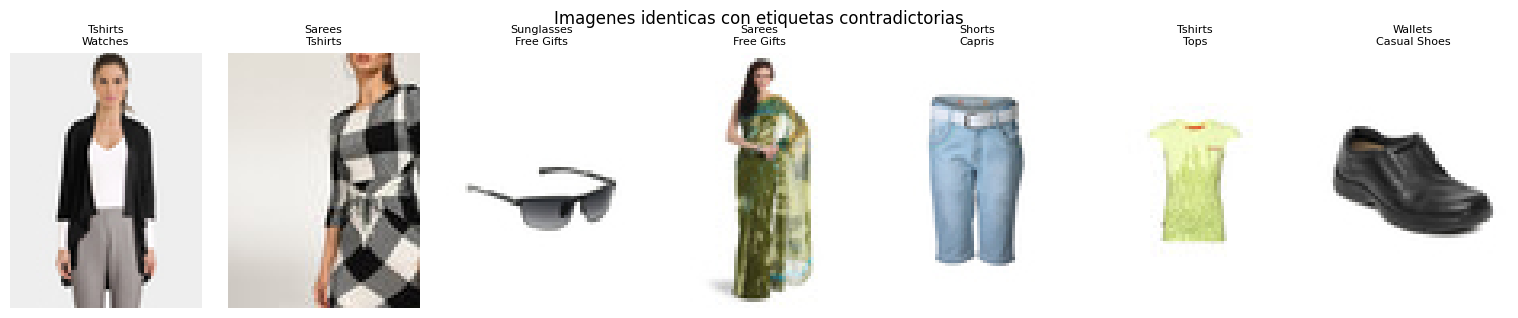

In [ ]:
###CORRECCION#
# Evidencia visual: misma imagen, etiquetas distintas
grupos = list(conflictos.groupby("md5"))
fig, axes = plt.subplots(1, len(grupos), figsize=(2.2 * len(grupos), 3.2))
for ax, (_, g) in zip(axes, grupos):
    ax.imshow(mpimg.imread(g["image_path"].iloc[0]), cmap="gray")
    ax.set_title("\n".join(g["articleType"].tolist()), fontsize=8)
    ax.axis("off")
plt.suptitle("Imagenes identicas con etiquetas contradictorias")
plt.tight_layout()
plt.show()

Aunque no hay `id` ni filas repetidas, sí hay **779 copias exactas de imágenes** (652 grupos, 1,431 imágenes involucradas), concentradas en Shirts y Tshirts. Siete grupos tienen etiquetas contradictorias (por ejemplo, la misma foto etiquetada como *Wallets* y como *Casual Shoes*), lo que confirma errores de etiquetado en el origen.

Esto importa porque, si una copia queda en entrenamiento y otra en prueba, el modelo "ve" la respuesta y las métricas se inflan. **Decisión:** eliminar por completo los grupos contradictorios, porque no se puede saber cuál etiqueta es correcta, y conservar una sola imagen por huella en el resto (se aplica al final, en el conjunto para modelar). *Limitación:* este método solo detecta copias idénticas byte a byte, no fotos casi iguales.

## Correspondencia imagen–metadato
En este caso estaremos viendo las imagenes que tienen imagenes faltantes y la información de dichas imagenes que se contienen.

In [ ]:
missing_images = df[~df["image_exists"]]

print(f"Cobertura imagen-metadato: {df['image_exists'].mean()*100:.2f}%")
print(f"Registros sin imagen: {len(missing_images)} de {len(df)}")

missing_images[["id", "gender", "masterCategory", "subCategory", "articleType", "productDisplayName"]]

Cobertura imagen-metadato: 99.99%
Registros sin imagen: 5 de 44446


,id,gender,masterCategory,subCategory,articleType,productDisplayName
6697,39403,Men,Apparel,Topwear,Shirts,U.S. Polo Assn. Men Black Tailored Fit Casual ...
16207,39410,Men,Apparel,Topwear,Shirts,U.S. Polo Assn. Men Cream-Coloured Tailored Fi...
32324,39401,Men,Apparel,Bottomwear,Jeans,U.S. Polo Assn. Denim Co. Men Blue Slim Straig...
36399,39425,Men,Apparel,Topwear,Tshirts,U.S. Polo Assn. Men Red Polo T-Shirt
40022,12347,Men,Apparel,Topwear,Suits,Fastrack Men Red Manhattan Regular Fit Solid F...


Se verificó la existencia física de la imagen correspondiente a cada registro del CSV, obteniendo una cobertura del 99.99%. Los 5 registros sin imagen corresponden a productos de las categorías Shirts, Jeans, Tshirts y Suits, todos dentro de masterCategory "Apparel". Dado que representan una fracción marginal del dataset 0.01% y no se concentran en ninguna clase particular que pudiera verse afectada de forma significativa, se descartan del conjunto de entrenamiento sin comprometer la representatividad de los datos.

In [ ]:
# Descartar los registros sin imagen correspondiente
df = df[df["image_exists"]].reset_index(drop=True)

print("Dimensiones despues de descartar registros sin imagen:", df.shape)

Dimensiones despues de descartar registros sin imagen: (44441, 13)


## Consistencia de las etiquetas

Se revisan los valores únicos de las variables categóricas candidatas a variable objetivo, para detectar inconsistencias de escritura

In [ ]:
categorical_cols = ["gender", "masterCategory", "subCategory", "articleType", "baseColour", "season", "usage"]

for col in categorical_cols:
    n_unique = df[col].nunique(dropna=True)
    print(f"{col}: {n_unique} valores unicos")
    print(sorted(df[col].dropna().unique())[:15], "...\n" if n_unique > 15 else "\n")

gender: 5 valores unicos
['Boys', 'Girls', 'Men', 'Unisex', 'Women'] 

masterCategory: 7 valores unicos
['Accessories', 'Apparel', 'Footwear', 'Free Items', 'Home', 'Personal Care', 'Sporting Goods'] 

subCategory: 45 valores unicos
['Accessories', 'Apparel Set', 'Bags', 'Bath and Body', 'Beauty Accessories', 'Belts', 'Bottomwear', 'Cufflinks', 'Dress', 'Eyes', 'Eyewear', 'Flip Flops', 'Fragrance', 'Free Gifts', 'Gloves'] ...

articleType: 142 valores unicos
['Accessory Gift Set', 'Baby Dolls', 'Backpacks', 'Bangle', 'Basketballs', 'Bath Robe', 'Beauty Accessory', 'Belts', 'Blazers', 'Body Lotion', 'Body Wash and Scrub', 'Booties', 'Boxers', 'Bra', 'Bracelet'] ...

baseColour: 47 valores unicos
['Beige', 'Black', 'Blue', 'Bronze', 'Brown', 'Burgundy', 'Charcoal', 'Coffee Brown', 'Copper', 'Cream', 'Fluorescent Green', 'Gold', 'Green', 'Grey', 'Grey Melange'] ...

season: 5 valores unicos
['', 'Fall', 'Spring', 'Summer', 'Winter'] 

usage: 10 valores unicos
['', 'Casual', 'Ethnic', 'For


Se detectó una inconsistencia en la representación de valores faltantes: las columnas `season` y `usage` codifican datos ausentes tanto como cadenas vacías (`''`) como mediante el texto literal `'NA'`, y al revisar todas las columnas también aparecen valores `'NA'` en `baseColour` y `productDisplayName`. Esto provocó que el conteo inicial de valores nulos subestimara la cantidad real de datos faltantes. En la siguiente celda se cuantifican y se unifican como `NaN`.

In [ ]:
###CORRECCION##
valores_vacios_season = df[df['season']=='']
print('Valores vacios en la columna season : ',valores_vacios_season.shape)
valores_vacios_usage = df[df['usage']=='']
print('Valores vacios en la columna usage : ',valores_vacios_usage.shape)
valores_na_usage = df[df['usage']=='NA']
print("Valores 'NA' en la columna usage : ",valores_na_usage.shape)
valores_na_color = df[df['baseColour']=='NA']
print("Valores 'NA' en la columna baseColour : ",valores_na_color.shape)
valores_na_nombre = df[df['productDisplayName']=='NA']
print("Valores 'NA' en la columna productDisplayName : ",valores_na_nombre.shape)

# Limpieza aplicada: se unifican las representaciones de ausencia como NaN
cols_con_ausencias = ['season', 'usage', 'year', 'baseColour', 'productDisplayName']
df[cols_con_ausencias] = df[cols_con_ausencias].replace(['', 'NA'], np.nan)
print('\nValores faltantes despues de unificar:')
print(df[cols_con_ausencias].isna().sum())

Valores vacios en la columna season :  (21, 13)
Valores vacios en la columna usage :  (1, 13)
Valores 'NA' en la columna usage :  (316, 13)
Valores 'NA' en la columna baseColour :  (15, 13)
Valores 'NA' en la columna productDisplayName :  (7, 13)

Valores faltantes despues de unificar:
season                 21
usage                 317
year                    1
baseColour             15
productDisplayName      7
dtype: int64


Al revisar las inconsistencias de los valores faltantes, se presentan 21 valores `('')` en la columna `season`; es más alarmante la columna `usage`, donde se encontraron 316 valores `('NA')` y un valor `('')`. Además, `baseColour` tiene 15 valores `('NA')` y `productDisplayName` 7. Estos valores ya quedaron unificados como `NaN` sobre el dataframe, de modo que cualquier uso posterior los cuenta correctamente. Como ninguna de estas columnas es entrada del modelo, no fue necesario eliminar registros.

## Balance de clases

El balance de clases es un criterio clave de calidad ya que clases muy minoritarias dificultan el entrenamiento y pueden requerir estrategias de remuestreo o agrupación de categorías poco frecuentes.

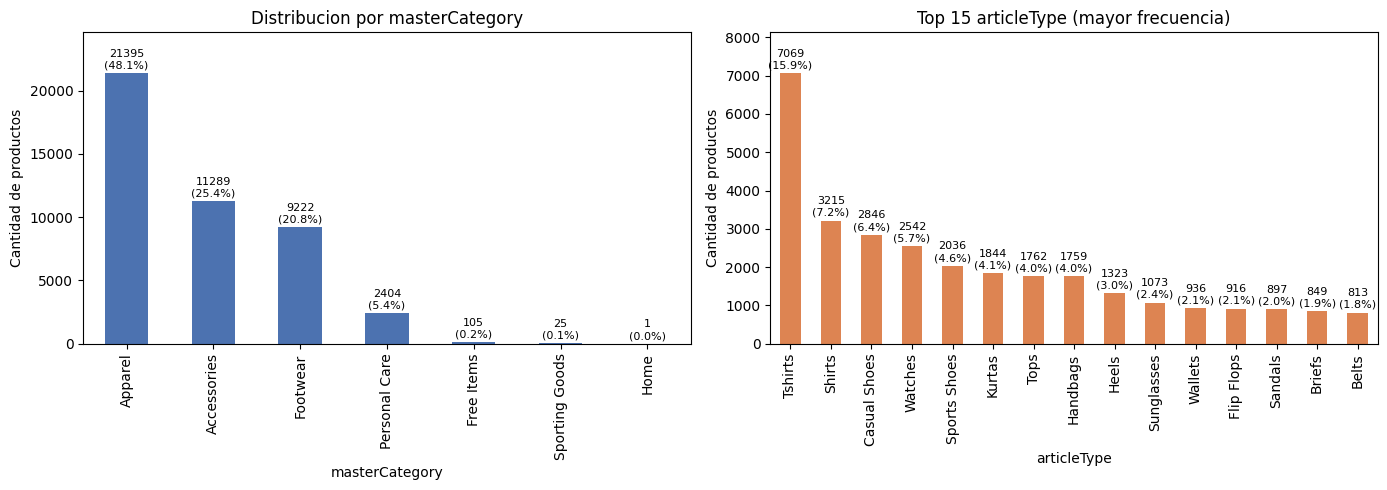

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Gráfico 1: masterCategory ---
master_counts = df["masterCategory"].value_counts()
master_pct = master_counts / master_counts.sum() * 100

master_counts.plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribucion por masterCategory")
axes[0].set_ylabel("Cantidad de productos")

for i, (count, pct) in enumerate(zip(master_counts, master_pct)):
    axes[0].text(i, count + master_counts.max()*0.01, f"{count}\n({pct:.1f}%)",
                 ha="center", va="bottom", fontsize=8)

axes[0].margins(y=0.15)

# --- Gráfico 2: Top 15 articleType ---
article_counts_all = df["articleType"].value_counts()
top_article_types = article_counts_all.head(15)
top_article_pct = top_article_types / article_counts_all.sum() * 100

top_article_types.plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Top 15 articleType (mayor frecuencia)")
axes[1].set_ylabel("Cantidad de productos")

for i, (count, pct) in enumerate(zip(top_article_types, top_article_pct)):
    axes[1].text(i, count + top_article_types.max()*0.01, f"{count}\n({pct:.1f}%)",
                 ha="center", va="bottom", fontsize=8)

axes[1].margins(y=0.15)

plt.tight_layout()
plt.show()

La distribución de clases evidencia un desbalance en ambos niveles de granularidad. A nivel de `masterCategory`, "Apparel" concentra cerca del 48% de los productos, mientras que categorías como "Home" o "Sporting Goods" representan una fracción marginal del dataset. A nivel de `articleType`, el desbalance es aún más pronunciado, la clase más frecuente es "Tshirts" con apróximadamente 7,069 productos, supera ampliamente a la mayoría de las demás, y es previsible que un número considerable de las 142 clases tenga muy pocos ejemplos, lo cual dificultaría entrenar un clasificador confiable para esas clases minoritarias.

In [ ]:
article_counts = df["articleType"].value_counts()

print("Numero total de clases (articleType):", article_counts.shape[0])
print("Clase mas frecuente:", article_counts.idxmax(), "->", article_counts.max(), "registros")
print("Clase menos frecuente:", article_counts.idxmin(), "->", article_counts.min(), "registro(s)")
print("Clases con menos de 20 registros:", (article_counts < 20).sum())

# Razon de desbalance: clase mayoritaria / clase minoritaria
print(f"Razon de desbalance (max/min): {article_counts.max() / article_counts.min():.1f}x")

Numero total de clases (articleType): 142
Clase mas frecuente: Tshirts -> 7069 registros
Clase menos frecuente: Shoe Laces -> 1 registro(s)
Clases con menos de 20 registros: 52
Razon de desbalance (max/min): 7069.0x


En este caso pudimos ver en `articleType` que se muestra un desbalance extremo, de las 142 clases presentes, la más frecuente son Tshirts con 7,069 registros que supera en 7,069 veces a la menos frecuente cómo lo son Shoe Laces con 1 registro. Además, 52 clases es decir un 36.6% del total cuentan con menos de 20
registros, un volumen insuficiente para dividir en conjuntos de entrenamiento, validación y prueba de forma confiable. Este hallazgo condiciona directamente la definición de la variable objetivo, entrenar un clasificador sobre las 142 clases de articleType sin ningún tratamiento previo no es viable con este dataset, por lo que en etapas posteriores será necesario agrupar categorías poco frecuentes o aplicar técnicas para el caso.

## Decisión del nivel de la variable objetivo

In [ ]:
###CORRECCION##
# Los conteos se hacen sobre imagenes unicas (sin copias exactas ni grupos con etiquetas contradictorias)
unicas = df[~df["md5"].isin(md5_conflicto)].drop_duplicates("md5")

niveles = pd.DataFrame([{
    "nivel": col,
    "clases": unicas[col].nunique(),
    "clase_min": int(unicas[col].value_counts().min()),
    "razon_desbalance": round(unicas[col].value_counts().max() / unicas[col].value_counts().min(), 1),
} for col in ["masterCategory", "subCategory", "articleType"]])
display(niveles)

conteo_unicas = unicas["articleType"].value_counts()
alternativas = []
for umbral in [20, 50, 100, 200, 300, 500, 1000]:
    k = conteo_unicas[conteo_unicas >= umbral]
    alternativas.append({
        "umbral_min_imagenes": umbral,
        "clases": len(k),
        "cobertura_catalogo_%": round(k.sum() / len(unicas) * 100, 1),
        "imagenes_min_en_prueba_(15%)": int(k.min() * 0.15),
        "razon_desbalance": round(k.max() / k.min(), 1),
    })
display(pd.DataFrame(alternativas))

UMBRAL_CLASE = 200
CLASES = sorted(conteo_unicas[conteo_unicas >= UMBRAL_CLASE].index)
print(f"Clases seleccionadas (>= {UMBRAL_CLASE} imagenes): {len(CLASES)}")
print("\nClases alrededor del corte:")
print(conteo_unicas[(conteo_unicas > 150) & (conteo_unicas < 260)])

,nivel,clases,clase_min,razon_desbalance
0,masterCategory,7,1,20657.0
1,subCategory,45,1,14812.0
2,articleType,142,1,6868.0


,umbral_min_imagenes,clases,cobertura_catalogo_%,imagenes_min_en_prueba_(15%),razon_desbalance
0,20,90,99.1,3,343.4
1,50,70,97.5,7,132.1
2,100,55,95.0,15,68.0
3,200,40,90.3,34,30.0
4,300,31,84.9,45,22.6
5,500,22,76.8,75,13.7
6,1000,10,56.9,158,6.5


Clases seleccionadas (>= 200 imagenes): 40

Clases alrededor del corte:
articleType
Jackets                255
Innerwear Vests        242
Kurtis                 234
Tunics                 229
Nightdress             189
Pendant                175
Leggings               167
Necklace and Chains    160
Name: count, dtype: int64


**Decisión:** la variable objetivo es `articleType` **restringida a las clases con al menos 200 imágenes únicas**: 40 clases que cubren el 90.3% del catálogo, con una razón de desbalance de 30x (frente a 7,069x original).

- **Por qué no `masterCategory` (7 clases):** es demasiado general para el vendedor (`Apparel` mezcla camisas, jeans y vestidos) y tiene clases con 1 registro (`Home`).
- **Por qué no `subCategory` (45 clases):** `Topwear` agrupa camisas, camisetas, kurtas y blusas, así que el vendedor igual tendría que elegir el tipo; además conserva clases con muy pocos registros.
- **Por qué 200:** con una partición 70/15/15 cada clase conserva al menos 34 imágenes en prueba, suficiente para estimar el desempeño por clase. Con 100 quedarían 15 y con 500 se excluiría casi una cuarta parte del catálogo. Además hay un corte natural entre *Tunics* (229) y *Nightdress* (189).
- **Por qué no agrupar el resto en "Otros":** esa clase mezclaría anillos, balones y lociones, sin coherencia visual.
- **Qué pasa con el ~10% restante:** queda fuera del alcance del clasificador y se cataloga manualmente, o se implementa una sub base que seria el 90.3% del que si podemos cubrir
- **Métrica principal para la Unidad 2:** F1-macro, porque con 30x de desbalance la exactitud quedaría dominada por *Tshirts*.

## Integridad de las imágenes

En este caso estaremos revisando que las imagenes no estén corrompidas

In [ ]:
###CORRECCION##
from PIL import Image

# Se revisan TODAS las imagenes (no una muestra) y el resultado se guarda en el dataframe
sizes = []
modes = []
corrupted = []

for img_path in df["image_path"]:
    try:
        with Image.open(img_path) as im:
            im.verify()  # valida integridad del archivo
        with Image.open(img_path) as im:
            sizes.append(im.size)   # (width, height)
            modes.append(im.mode)   # RGB, L, CMYK, etc.
    except Exception as e:
        sizes.append((np.nan, np.nan))
        modes.append(None)
        corrupted.append((img_path, str(e)))

df["modo"] = modes
df["tamano"] = sizes

print(f"Imagenes analizadas: {len(df)} (todas)")
print(f"Imagenes corruptas detectadas: {len(corrupted)}")
print(f"Modos de color encontrados: {set(modes)}")

sizes_arr = np.array(sizes)
print(f"Resolucion minima: {sizes_arr.min(axis=0)}")
print(f"Resolucion maxima: {sizes_arr.max(axis=0)}")
print(f"Resolucion mas comun: {pd.Series([tuple(s) for s in sizes]).mode()[0]}")

print("\nResoluciones encontradas (ancho, alto):")
print(df["tamano"].value_counts())
n_otra_resolucion = int(df["tamano"].apply(lambda s: s != (60, 80)).sum())
print(f"\nImagenes que NO miden 60x80: {n_otra_resolucion}")

Imagenes analizadas: 44441 (todas)
Imagenes corruptas detectadas: 0
Modos de color encontrados: {'L', 'RGB'}
Resolucion minima: [53 60]
Resolucion maxima: [60 80]
Resolucion mas comun: (60, 80)

Resoluciones encontradas (ancho, alto):
tamano
(60, 80)    44418
(53, 80)       10
(60, 60)        5
(54, 80)        2
(60, 79)        2
(60, 77)        2
(60, 75)        1
(60, 76)        1
Name: count, dtype: int64

Imagenes que NO miden 60x80: 23


In [ ]:
modes_series = pd.Series(modes)

print("--- Conteo por modo ---")
print(modes_series.value_counts())

print("\n--- Proporción (%) por modo ---")
print(modes_series.value_counts(normalize=True) * 100)

--- Conteo por modo ---
RGB    44010
L        431
Name: count, dtype: int64

--- Proporción (%) por modo ---
RGB    99.030175
L       0.969825
Name: proportion, dtype: float64


En este caso, realizando la prueba sobre todo el dataset de imágenes (las 44,441, no una muestra), no encontramos archivos corruptos. Sin embargo, no todas las imágenes comparten la resolución de 60x80 píxeles: 23 tienen otra resolución (por ejemplo 53x80 o 60x60), por lo que en el preprocesamiento deberán redimensionarse para poder formar el tensor de entrada. También encontramos una inconsistencia en el modo de color: la mayoría están en formato RGB, pero 431 están en escala de grises (modo L). Por lo cual toca convertirlas al mismo formato (RGB); a continuación se revisa en qué clases se concentran.

In [ ]:
###CORRECCION##
# Distribucion de las imagenes en escala de grises (modo L) por clase
gris = df[df["modo"] == "L"]
print("Imagenes en modo L:", len(gris))
print("\nPor masterCategory:")
print(gris["masterCategory"].value_counts())

tabla_gris = pd.DataFrame({
    "imagenes_L": gris["articleType"].value_counts(),
    "total_clase": df["articleType"].value_counts(),
}).dropna().astype(int)
tabla_gris["pct_L_en_clase"] = (tabla_gris["imagenes_L"] / tabla_gris["total_clase"] * 100).round(1)
tabla_gris["clase_modelada"] = tabla_gris.index.isin(CLASES)
tabla_gris = tabla_gris.sort_values("imagenes_L", ascending=False)
tabla_gris.head(20)

Imagenes en modo L: 431

Por masterCategory:
masterCategory
Accessories      275
Footwear         102
Apparel           46
Personal Care      7
Free Items         1
Name: count, dtype: int64


,imagenes_L,total_clase,pct_L_en_clase,clase_modelada
articleType,,,,
Watches,80,2542,3.1,True
Wallets,39,936,4.2,True
Casual Shoes,30,2846,1.1,True
Handbags,25,1759,1.4,True
Belts,23,813,2.8,True
Socks,22,686,3.2,True
Sandals,20,897,2.2,True
Backpacks,19,724,2.6,True
Formal Shoes,18,637,2.8,True


Las 431 imágenes en grises se concentran en **Accessories (275)** y **Footwear (102)**; *Watches* (80) y *Wallets* (39) aportan la mayor cantidad. La proporción más alta está en *Ring* (11.9%), *Cufflinks* (5.7%) y *Pendant* (5.1%), clases que quedan por debajo del umbral de modelado. Dentro de las clases modeladas ninguna supera ~4.2% (*Wallets*).

**Conclusión:** estandarizar el color es **crítico en lo técnico**, porque la CNN espera 3 canales y no se puede formar un tensor con imágenes de 1 y 3 canales mezcladas, pero es **de bajo riesgo de sesgo**, porque la escala de grises no está asociada fuertemente a ninguna clase modelada. En el preprocesamiento se convertirán a RGB replicando el canal.

## Resumen de calidad del dataset

In [ ]:
quality_summary = pd.DataFrame({
    "Criterio": [
        "Registros en el CSV",
        "Registros con imagen (tras descartar 5)",
        "Total de imagenes en disco",
        "Cobertura imagen-metadato",
        "Filas con formato de CSV corregido",
        "IDs duplicados",
        "Copias exactas de imagen (MD5)",
        "Grupos con etiquetas contradictorias",
        "Ausencias codificadas como '' o 'NA'",
        "Numero de clases (articleType)",
        "Razon de desbalance (max/min)",
        "Imagenes corruptas (44,441 revisadas)",
        "Imagenes con resolucion distinta a 60x80",
        "Imagenes en escala de grises (modo L)",
        "Clases modeladas (>= 200 imagenes unicas)",
    ],
    "Valor": [
        len(rows),
        len(df),
        int(df["image_exists"].sum()),
        f"{df['image_exists'].mean()*100:.2f}%",
        len(problematic_rows),
        int(dup_ids),
        int(df["md5"].duplicated().sum()),
        len(md5_conflicto),
        int(missing_summary[["cadena_vacia", "texto_NA"]].values.sum()),
        int(df["articleType"].nunique()),
        f"{article_counts.max() / article_counts.min():.1f}x",
        len(corrupted),
        n_otra_resolucion,
        int((df["modo"] == "L").sum()),
        len(CLASES),
    ]
})

quality_summary

,Criterio,Valor
0,Registros en el CSV,44446
1,Registros con imagen (tras descartar 5),44441
2,Total de imagenes en disco,44441
3,Cobertura imagen-metadato,100.00%
4,Filas con formato de CSV corregido,22
5,IDs duplicados,0
6,Copias exactas de imagen (MD5),779
7,Grupos con etiquetas contradictorias,7
8,Ausencias codificadas como '' o 'NA',361
9,Numero de clases (articleType),142


In [ ]:

# Conjunto resultante para modelar: se aplican las decisiones de duplicados y de variable objetivo
paso1 = df[~df["md5"].isin(md5_conflicto)]
paso2 = paso1.drop_duplicates(subset="md5", keep="first")
df_model = paso2[paso2["articleType"].isin(CLASES)].reset_index(drop=True)

embudo = pd.DataFrame({
    "paso": ["Registros en el CSV", "Con imagen en disco", "Sin grupos de etiqueta contradictoria",
             "Sin copias exactas (1 por imagen)", f"Clases con >= {UMBRAL_CLASE} imagenes unicas"],
    "registros": [len(rows), len(df), len(paso1), len(paso2), len(df_model)],
})
embudo["retenido_%"] = (embudo["registros"] / len(rows) * 100).round(1)
display(embudo)

df_model[["id", "articleType", "masterCategory", "subCategory", "gender", "baseColour", "modo", "md5"]] \
    .to_csv("dataset_modelo.csv", index=False)
print(f"Clases: {df_model['articleType'].nunique()} | Imagenes para modelar: {len(df_model)}")
print("Archivo guardado para la Unidad 2: dataset_modelo.csv")

,paso,registros,retenido_%
0,Registros en el CSV,44446,100.0
1,Con imagen en disco,44441,100.0
2,Sin grupos de etiqueta contradictoria,44427,100.0
3,Sin copias exactas (1 por imagen),43655,98.2
4,Clases con >= 200 imagenes unicas,39437,88.7


Clases: 40 | Imagenes para modelar: 39437
Archivo guardado para la Unidad 2: dataset_modelo.csv



Después de la depuración inicial, en la cual se descartaron los 5 registros que no contaban con imagen correspondiente, el dataset quedó con 44,441 registros en el CSV y sus respectivas imágenes en disco. Con esta depuración se alcanzó una cobertura imagen-metadato del 100%, frente al 99.99% inicial. No se encontraron imágenes corruptas en ninguna de las 44,441 imágenes revisadas.

La revisión también encontró problemas que el conteo estándar no detecta: ausencias escritas como `''` o `'NA'` en cinco columnas (ya unificadas como `NaN`), 779 copias exactas de imágenes con 7 grupos de etiquetas contradictorias (ya excluidas del conjunto para modelar), 23 imágenes con resolución distinta a 60x80 y 431 en escala de grises (se estandarizarán en el preprocesamiento).

Adicionalmente, se identificaron 142 clases en la variable `articleType`, con un desbalance extremo de 7,069x entre la clase más y menos frecuente. Por eso la variable objetivo quedó restringida a las 40 clases con al menos 200 imágenes únicas: 39,437 imágenes, 90.3% del catálogo y un desbalance de 30x.

Con este diagnóstico, el dataset queda listo para avanzar a la siguiente etapa del proyecto, en la que se hará la partición en entrenamiento, validación y prueba, la estandarización de las imágenes (RGB y 80x60) y el entrenamiento del modelo base CNN definido en el objetivo del proyecto.

## Organización y distribución del trabajo en equipo

Este trabajo lo estuvimos desarrolando de forma colaborativa entre tres integrantes, con roles definidos, los integrantes son:

* Julian — Analista de datos

Extracción y limpieza inicial del dataset.
Verificación de completitud (valores nulos) y unicidad (duplicados).
Correspondencia imagen–metadato y descarte de los registros sin imagen asociada.

* Kinan — Deep Learning Engineer

Justificación del uso de una CNN frente a alternativas lineales, con base en la naturaleza de los datos de imagen.
Análisis de integridad de las imágenes: verificación de corrupción, resolución y modos de color (RGB vs. escala de grises).
Definición del alcance técnico del proyecto y su proyección hacia las siguientes etapas.

* Ivanna — Analista de datos / liderazgo del proyecto

Planteamiento y contextualización del problema de negocio, identificación de stakeholders y objetivos de negocio/técnicos.
Consistencia de etiquetas y análisis de balance de clases, además de la consistencia del texto, es decir ver si algunas variables se estaban escribiendo de la misma forma.
Coordinación general del equipo, integración de las secciones del notebook y revisión final del documento.

El equipo se coordinó mediante reuniones periódicas de seguimiento para validar avances, resolver dudas conceptuales y alinear los criterios de calidad aplicados al dataset. Las tareas se dividieron según la etapa del ciclo CRISP-DM (comprensión del negocio vs. comprensión de los datos) y el perfil de cada integrante, y todos participaron en la revisión cruzada del notebook y de las diapositivas finales antes de la entrega.

## Declaración de uso de herramientas de IA

En la corrección de esta entrega el equipo utilizó diversas plataformas IA como apoyo para revisar el código, sugerir verificaciones adicionales de calidad (duplicados exactos de imágenes, resoluciones distintas a 60x80 y valores `'NA'` en otras columnas).

# Recordatorio del problema

Esta entrega corresponde al primer hito técnico del proyecto: construir, entrenar y evaluar un **modelo base funcional** que permita validar la viabilidad técnica de la solución formulada en la Unidad 1.

- **Pregunta analítica:** ¿es posible predecir automáticamente el tipo de artículo de un producto de moda a partir de su imagen, para automatizar la catalogación en una plataforma de e-commerce?
- **Variable objetivo (y):** `articleType`, restringida en la Unidad 1 a las **40 clases con al menos 200 imágenes únicas** (39,437 imágenes, 90.3 % del catálogo, desbalance 30:1).
- **Variable de entrada (X):** la imagen del producto, como tensor RGB de 80 × 60 × 3 normalizado en [0, 1]. Los metadatos no se usan como entrada (algunos filtran la respuesta, como `subCategory` o `productDisplayName`).
- **Métrica principal:** F1-macro, definida en la Unidad 1 porque con un desbalance de 30:1 la accuracy queda dominada por *Tshirts*. Se complementa con accuracy y F1-weighted.
- **Relación con el negocio:** un modelo con buen F1-macro puede sugerir la categoría al vendedor en el momento de publicar el producto, reduciendo el tiempo de catalogación manual y los errores de clasificación del catálogo, que son los objetivos de negocio planteados.


In [ ]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
images_path = os.path.join(path, "myntradataset", "images")

# Dataset depurado en la Unidad 1
df_model = pd.read_csv("dataset_modelo.csv")
df_model["image_path"] = df_model["id"].apply(lambda x: os.path.join(images_path, f"{x}.jpg"))
df_model = df_model[df_model["image_path"].apply(os.path.exists)].reset_index(drop=True)

print("Registros disponibles para modelar:", len(df_model))
print("Clases (articleType):", df_model["articleType"].nunique())
df_model["articleType"].value_counts().tail(10)  # las clases menos representadas

Registros disponibles para modelar: 39437
Clases (articleType): 40


,count
articleType,
Track Pants,304
Clutches,290
Sweatshirts,283
Caps,282
Sweaters,277
Ties,263
Jackets,255
Innerwear Vests,242
Kurtis,234


In [ ]:
counts = df_model["articleType"].value_counts()
print("Clase mayoritaria:", counts.idxmax(), "->", counts.max())
print("Clase minoritaria:", counts.idxmin(), "->", counts.min())
print("Razon de desbalance (max/min):", round(counts.max() / counts.min(), 1))

Clase mayoritaria: Tshirts -> 6868
Clase minoritaria: Tunics -> 229
Razon de desbalance (max/min): 30.0


El dataset presenta un desbalance considerable en la distribución de clases, con una proporción aproximada de 30:1 entre la clase mayoritaria Tshirts (6.868 imágenes) y la minoritaria Tunics (229 imágenes). Esta diferencia en la cantidad de muestras puede favorecer que el modelo base se ajuste predominantemente a las características de las clases más representadas, dificultando el aprendizaje de patrones distintivos de las clases minoritarias. En consecuencia, se anticipa que este desbalance podría afectar la capacidad de generalización del modelo, especialmente en aquellas categorías con menor representación, lo que hace necesario analizar su desempeño mediante métricas complementarias a la exactitud (accuracy).

## División train/validation/test

In [ ]:
train_df, temp_df = train_test_split(
    df_model, test_size=0.30, stratify=df_model["articleType"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["articleType"], random_state=SEED
)

print("Train:", len(train_df), "| Val:", len(val_df), "| Test:", len(test_df))

Train: 27605 | Val: 5916 | Test: 5916


En este caso la división quedará train con un total de 27.605, validación con un valor de 5.916 y test con un valor de 5.916

## Normalización y pipeline de imágenes

In [ ]:
IMG_SIZE = (80, 60)
BATCH_SIZE = 64

train_datagen = ImageDataGenerator(rescale=1./255, horizontal_flip=True)
eval_datagen = ImageDataGenerator(rescale=1./255)

def make_generator(datagen, dataframe, shuffle):
    return datagen.flow_from_dataframe(
        dataframe=dataframe,
        x_col="image_path",
        y_col="articleType",
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=shuffle,
        seed=SEED,
    )

train_gen = make_generator(train_datagen, train_df, shuffle=True)
val_gen = make_generator(eval_datagen, val_df, shuffle=False)
test_gen = make_generator(eval_datagen, test_df, shuffle=False)

NUM_CLASSES = len(train_gen.class_indices)
print("Numero de clases detectadas por el generador:", NUM_CLASSES)

Found 27605 validated image filenames belonging to 40 classes.
Found 5916 validated image filenames belonging to 40 classes.
Found 5916 validated image filenames belonging to 40 classes.
Numero de clases detectadas por el generador: 40


Los tres generadores de datos (entrenamiento, validación y prueba) identificaron correctamente las 40 categorías de articleType, lo que evidencia que la partición estratificada conservó la representación de todas las clases en cada subconjunto, incluidas las minoritarias, como Tunics (229 imágenes). Asimismo, la suma de las imágenes validadas en los tres conjuntos (27.605 de entrenamiento, 5.916 de validación y 5.916 de prueba) corresponde exactamente a las 39.437 imágenes del dataset depurado. Esta coincidencia confirma que todas las imágenes fueron contabilizadas durante la validación, sin pérdidas ni errores de carga reportados.

## Arquitectura y configuración del modelo base

Como modelo base se utilizará una CNN secuencial sin técnicas adicionales de regularización o aumento de datos, con el propósito de establecer una referencia de desempeño para las comparaciones posteriores. Su arquitectura estará conformada por tres bloques convolucionales con 32, 64 y 128 filtros, respectivamente, cada uno integrado por las capas Conv2D, BatchNormalization y MaxPooling2D. Posteriormente, se incorporará una capa densa de 128 neuronas, seguida de Dropout con una tasa de 0.4 y una capa de salida softmax con 40 neuronas, una por cada categoría de articleType.

El entrenamiento se realizará utilizando categorical_crossentropy como función de pérdida y Adam con una tasa de aprendizaje de 1×10⁻³. Se establecerá un tamaño de lote (batch size) de 64 y un máximo de 15 épocas. Adicionalmente, se implementará EarlyStopping, con una paciencia de 3 épocas y monitoreo de val_loss, para detener el proceso cuando la pérdida de validación deje de mejorar, evitando iteraciones innecesarias y contribuyendo al control del sobreajuste.

Nota: Aunque se denomina modelo base, ya incorpora Dropout y BatchNormalization. Por tanto, es más preciso describirlo como una configuración de referencia con regularización interna, sobre la cual se evaluarán posteriormente otras estrategias.

In [ ]:
def build_base_model(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation="softmax"),
    ])
    return model

model = build_base_model(input_shape=(*IMG_SIZE, 3), num_classes=NUM_CLASSES)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 80, 60, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 80, 60, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 40, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 40, 30, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 40, 30, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 15, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 20, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 7, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8960)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,147,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         5,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,246,312 (4.75 MB)

 Trainable params: 1,245,864 (4.75 MB)

 Non-trainable params: 448 (1.75 KB)

## Protocolo de comparación de modificaciones al modelo base

El objetivo de esta sección es medir cuánto aporta cada modificación por separado frente al modelo base. Para que la comparación sea justa, **en cada experimento cambia un solo factor** y todo lo demás se mantiene idéntico al modelo base:

- Misma partición train/validation/test (70/15/15, estratificada, `SEED = 42`) y mismas imágenes de 80x60 (alto x ancho).
- Mismo `BATCH_SIZE = 64`, Adam, `categorical_crossentropy`, máximo de 15 épocas y `EarlyStopping` sobre `val_loss` con paciencia de 3.
- Misma semilla al inicio de cada entrenamiento y mismo orden de barajado del generador de entrenamiento.

**Métrica de decisión:** F1-macro sobre **validación**, que es la métrica principal definida en la Unidad 1 porque con un desbalance de 30x la exactitud queda dominada por *Tshirts*. Se reportan también accuracy y F1-weighted como complemento. El conjunto de **prueba no se usa para elegir**: solo se evalúa al final, para el modelo base y para la mejor modificación.

**Detalles que el modelo base no especificaba y que se aplican por igual a todos los experimentos:** `EarlyStopping` con `restore_best_weights=True` (se evalúa la mejor época y no la última) y una sola corrida por experimento.

**Modificaciones evaluadas (una a la vez):**

| # | Experimento | Único cambio respecto al base | Qué problema ataca |
|---|---|---|---|
| 0 | Base | Ninguno | Referencia con el que nos vamos a guíar|
| 1 | Class weights | `class_weight='balanced'` en `fit` | Desbalance 30:1 |
| 2 | Data augmentation | Rotación, desplazamiento y zoom en el generador de entrenamiento | Sobreajuste / pocas imágenes por clase |
| 3 | Dropout 0.6 | Dropout de 0.4 a 0.6 | Sobreajuste |
| 4 | Global Average Pooling | `GlobalAveragePooling2D` en lugar de `Flatten` | Exceso de parámetros en la capa densa |
| 5 | Bloque adicional | Cuarto bloque convolucional de 256 filtros | Capacidad del modelo |
| 6 | Learning rate 1e-4 | Tasa de aprendizaje de 1e-3 a 1e-4 | Estabilidad de la optimización |

### Funciones de apoyo: constructor de variantes y ejecutor de experimentos

In [ ]:
import time
from sklearn.metrics import f1_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping

MAX_EPOCHS = 15
PATIENCE = 3
resultados = {}   # nombre -> métricas, historial y modelo entrenado

def build_variant_model(input_shape, num_classes, filters=(32, 64, 128),
                        dense_units=128, dropout=0.4, pooling="flatten"):
    """Con los valores por defecto reproduce exactamente build_base_model."""
    capas = [layers.Input(shape=input_shape)]
    for f in filters:
        capas += [
            layers.Conv2D(f, (3, 3), activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
        ]
    capas += [
        layers.Flatten() if pooling == "flatten" else layers.GlobalAveragePooling2D(),
        layers.Dense(dense_units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(num_classes, activation="softmax"),
    ]
    return models.Sequential(capas)

# Verificación: con los valores por defecto debe ser idéntico al modelo base
_ref = build_variant_model((*IMG_SIZE, 3), NUM_CLASSES)
assert _ref.count_params() == model.count_params(), "La variante por defecto no coincide con el modelo base"
print("OK: build_variant_model() por defecto == modelo base ->", f"{_ref.count_params():,} parámetros")
del _ref

CLASES_ORDEN = sorted(val_gen.class_indices, key=val_gen.class_indices.get)

def run_experiment(nombre, descripcion, model_fn=None, datagen=None,
                   learning_rate=1e-3, class_weight=None):
    """Entrena un experimento. Todo lo no indicado queda igual al modelo base."""
    tf.keras.backend.clear_session()
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model_fn = model_fn or (lambda: build_variant_model((*IMG_SIZE, 3), NUM_CLASSES))
    datagen = datagen or train_datagen
    gen_train = make_generator(datagen, train_df, shuffle=True)   # generador nuevo: mismo orden en todos

    m = model_fn()
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    es = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)

    t0 = time.time()
    hist = m.fit(gen_train, validation_data=val_gen, epochs=MAX_EPOCHS,
                 callbacks=[es], class_weight=class_weight, verbose=2)
    minutos = (time.time() - t0) / 60

    y_true = val_gen.classes
    y_pred = m.predict(val_gen, verbose=0).argmax(axis=1)
    resultados[nombre] = {
        "descripcion": descripcion,
        "val_acc": accuracy_score(y_true, y_pred),
        "val_f1_macro": f1_score(y_true, y_pred, average="macro"),
        "val_f1_weighted": f1_score(y_true, y_pred, average="weighted"),
        "val_loss": min(hist.history["val_loss"]),
        "epocas": len(hist.history["loss"]),
        "parametros": m.count_params(),
        "minutos": minutos,
        "historial": hist.history,
        "modelo": m,
    }
    r = resultados[nombre]
    print(f"\n>>> {nombre}: val_acc={r['val_acc']:.4f} | val_F1-macro={r['val_f1_macro']:.4f} "
          f"| épocas={r['epocas']} | {minutos:.1f} min")

OK: build_variant_model() por defecto == modelo base -> 1,246,312 parámetros


## Experimento 0 - Modelo base (referencia)

Se reentrena el modelo base con el mismo ejecutor que usarán las modificaciones, de modo que la única diferencia entre experimentos sea el factor que se cambia.

In [ ]:
run_experiment("0. Base", "Ninguno (referencia)")

Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/15
432/432 - 31s - 72ms/step - accuracy: 0.4703 - loss: 1.8777 - val_accuracy: 0.5257 - val_loss: 1.4558
Epoch 2/15
432/432 - 16s - 38ms/step - accuracy: 0.6469 - loss: 1.1228 - val_accuracy: 0.5201 - val_loss: 1.8678
Epoch 3/15
432/432 - 18s - 41ms/step - accuracy: 0.7070 - loss: 0.9013 - val_accuracy: 0.6826 - val_loss: 1.1894
Epoch 4/15
432/432 - 19s - 44ms/step - accuracy: 0.7422 - loss: 0.7802 - val_accuracy: 0.7270 - val_loss: 0.8533
Epoch 5/15
432/432 - 16s - 38ms/step - accuracy: 0.7670 - loss: 0.7033 - val_accuracy: 0.7581 - val_loss: 0.9855
Epoch 6/15
432/432 - 17s - 40ms/step - accuracy: 0.7850 - loss: 0.6398 - val_accuracy: 0.7419 - val_loss: 0.8117
Epoch 7/15
432/432 - 16s - 38ms/step - accuracy: 0.8026 - loss: 0.5841 - val_accuracy: 0.7698 - val_loss: 0.7989
Epoch 8/15
432/432 - 17s - 38ms/step - accuracy: 0.8096 - loss: 0.5599 - val_accuracy: 0.8171 - val_loss: 0.5469
Epoch 9/15
432/432 - 19s - 44ms/s

### Métricas de entrenamiento y validación del modelo base

Se presentan las curvas de aprendizaje (train vs. validación) del modelo base y sus métricas en la mejor época, que es la que conserva `EarlyStopping(restore_best_weights=True)`.

*Nota:* las métricas de entrenamiento que registra Keras en cada época se calculan **con Dropout activo y con volteo horizontal**, por lo que subestiman el desempeño real en entrenamiento. Por eso, además se calcula el F1-macro de train y validación **en modo inferencia** (sin Dropout ni aumento), que es la comparación correcta para medir la brecha de generalización.

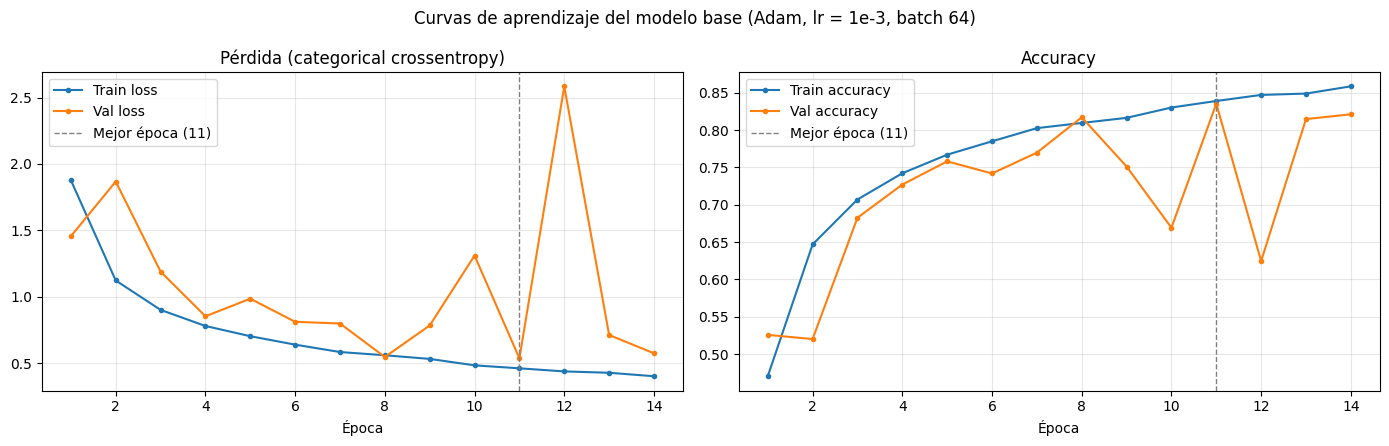

Métricas en la mejor época (11 de 14):


,Train,Validación,Brecha (val - train)
Loss,0.4615,0.5361,0.0746
Accuracy,0.8390,0.8354,-0.0036


Indicadores de convergencia y estabilidad:
  Train loss: 1.878 (época 1) -> 0.402 (época 14), descenso continuo
  Épocas en que el val loss sube respecto a la anterior: 5 de 13
  Mayor salto del val loss entre épocas: +2.048
  Oscilación del val loss (desv. estándar de los cambios, desde la época 3): 0.897
  Rango de val accuracy: 0.520 - 0.835
Found 27605 validated image filenames belonging to 40 classes.

Métricas en modo inferencia (mejores pesos del modelo base):


,accuracy,F1_macro,F1_weighted
conjunto,,,
Train (inferencia),0.8582,0.7900,0.8471
Validación,0.8354,0.7581,0.8223
Brecha (val - train),-0.0228,-0.0319,-0.0248


In [ ]:
# Historial del modelo base: se toma del entrenamiento en memoria; si la sesión de Colab se reinició,
# se usa el historial registrado en el log del entrenamiento (mismos valores, copiados de la salida anterior).
HIST_LOG = {"0. Base": {"loss": [1.8551, 1.0767, 0.873, 0.7719, 0.6874, 0.6223, 0.5736, 0.5356, 0.5078, 0.4737, 0.4508, 0.4367, 0.4137, 0.3877], "accuracy": [0.4696, 0.6541, 0.7165, 0.7452, 0.7693, 0.7884, 0.8, 0.8158, 0.8225, 0.8324, 0.8434, 0.8487, 0.8549, 0.8623], "val_loss": [1.4449, 1.1316, 1.414, 0.667, 0.6772, 0.5529, 0.8857, 0.546, 1.4939, 0.4992, 0.441, 0.6996, 0.5471, 0.6711], "val_accuracy": [0.5527, 0.6506, 0.5732, 0.7853, 0.7931, 0.8124, 0.6935, 0.8193, 0.6675, 0.8325, 0.8538, 0.8313, 0.8475, 0.789]}, "6. LR 1e-4": {"loss": [1.5994, 0.9286, 0.7412, 0.626, 0.5563, 0.4989, 0.4531, 0.407, 0.3774, 0.3494, 0.3189, 0.293, 0.2741, 0.2539], "accuracy": [0.5793, 0.7353, 0.7791, 0.8058, 0.8242, 0.839, 0.8515, 0.8663, 0.8728, 0.8824, 0.8882, 0.8981, 0.9039, 0.9105], "val_loss": [1.2292, 0.643, 0.5538, 0.525, 0.5147, 0.4785, 0.4808, 0.4599, 0.4445, 0.4392, 0.4277, 0.4477, 0.4518, 0.4293], "val_accuracy": [0.6829, 0.8065, 0.8288, 0.8386, 0.8374, 0.8442, 0.8475, 0.8546, 0.8575, 0.8573, 0.8619, 0.8631, 0.8619, 0.866]}}

def historial(nombre):
    if "resultados" in globals() and nombre in resultados:
        return resultados[nombre]["historial"]
    print(f"Aviso: '{nombre}' no está en memoria; se usa el historial registrado en el log.")
    return HIST_LOG[nombre]

h_base = historial("0. Base")
ep = np.arange(1, len(h_base["loss"]) + 1)
mejor = int(np.argmin(h_base["val_loss"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ep, h_base["loss"], marker="o", ms=3, label="Train loss")
axes[0].plot(ep, h_base["val_loss"], marker="o", ms=3, label="Val loss")
axes[1].plot(ep, h_base["accuracy"], marker="o", ms=3, label="Train accuracy")
axes[1].plot(ep, h_base["val_accuracy"], marker="o", ms=3, label="Val accuracy")
for ax, titulo in zip(axes, ["Pérdida (categorical crossentropy)", "Accuracy"]):
    ax.axvline(mejor + 1, ls="--", color="gray", lw=1, label=f"Mejor época ({mejor + 1})")
    ax.set_title(titulo); ax.set_xlabel("Época"); ax.grid(alpha=0.3); ax.legend()
plt.suptitle("Curvas de aprendizaje del modelo base (Adam, lr = 1e-3, batch 64)")
plt.tight_layout(); plt.show()

# Métricas en la mejor época (registradas por Keras)
tabla_base = pd.DataFrame({
    "Train": [h_base["loss"][mejor], h_base["accuracy"][mejor]],
    "Validación": [h_base["val_loss"][mejor], h_base["val_accuracy"][mejor]],
}, index=["Loss", "Accuracy"])
tabla_base["Brecha (val - train)"] = tabla_base["Validación"] - tabla_base["Train"]
print(f"Métricas en la mejor época ({mejor + 1} de {len(ep)}):")
display(tabla_base.round(4))

# Indicadores de convergencia y estabilidad
vl = np.array(h_base["val_loss"])
print("Indicadores de convergencia y estabilidad:")
print(f"  Train loss: {h_base['loss'][0]:.3f} (época 1) -> {h_base['loss'][-1]:.3f} (época {len(ep)}), descenso continuo")
print(f"  Épocas en que el val loss sube respecto a la anterior: {int((np.diff(vl) > 0).sum())} de {len(vl) - 1}")
print(f"  Mayor salto del val loss entre épocas: +{np.diff(vl).max():.3f}")
print(f"  Oscilación del val loss (desv. estándar de los cambios, desde la época 3): {np.std(np.diff(vl[2:])):.3f}")
print(f"  Rango de val accuracy: {min(h_base['val_accuracy']):.3f} - {max(h_base['val_accuracy']):.3f}")

# F1-macro en train y validación en modo inferencia (sin Dropout ni volteo), con los mejores pesos
try:
    m_base = resultados["0. Base"]["modelo"]
    train_eval_gen = make_generator(eval_datagen, train_df, shuffle=False)
    filas_f1 = []
    for nombre_split, gen in [("Train (inferencia)", train_eval_gen), ("Validación", val_gen)]:
        y_true = gen.classes
        y_pred = m_base.predict(gen, verbose=0).argmax(axis=1)
        filas_f1.append({"conjunto": nombre_split,
                         "accuracy": accuracy_score(y_true, y_pred),
                         "F1_macro": f1_score(y_true, y_pred, average="macro"),
                         "F1_weighted": f1_score(y_true, y_pred, average="weighted")})
    tabla_f1_base = pd.DataFrame(filas_f1).set_index("conjunto")
    tabla_f1_base.loc["Brecha (val - train)"] = tabla_f1_base.loc["Validación"] - tabla_f1_base.loc["Train (inferencia)"]
    print("\nMétricas en modo inferencia (mejores pesos del modelo base):")
    display(tabla_f1_base.round(4))
except (NameError, KeyError) as e:
    print("\nPara la tabla de F1 en train/validación se necesita el modelo base en memoria "
          "(ejecute la celda del Experimento 0).", e)


### Diagnóstico técnico del modelo base

**Convergencia.** El entrenamiento converge de forma sostenida: el train loss baja de 1.878 a 0.402 en 14 épocas y la train accuracy sube de 0.470 a 0.859, sin estancarse. El EarlyStopping se activó en la época 14 (mejor época: 11), pero no porque el modelo hubiera dejado de aprender, sino por el ruido de la curva de validación. Es decir, la convergencia quedó **incompleta**: con una validación más estable el modelo podría seguir mejorando.

**Estabilidad.** Es el principal problema del modelo base. Mientras el train loss baja de forma suave, el val loss oscila fuertemente ya que sube en 5 de las 13 transiciones entre épocas, con saltos de hasta +2.048 (de 0.536 en la época 11 a 2.585 en la época 12), y la val accuracy varía entre 0.520 y 0.835. Una validación tan inestable con un entrenamiento estable es característica de una **tasa de aprendizaje alta combinada con BatchNormalization**: los pasos grandes cambian mucho los pesos entre épocas y las estadísticas de normalización que se usan en inferencia no alcanzan a estabilizarse. El Experimento 6 lo confirma, con `lr = 1e-4` la oscilación del val loss cae de 0.897 a 0.053.

**Generalización.** No hay evidencia de sobreajuste en el modelo base. En la mejor época, la pérdida y la accuracy de validación (0.536 y 0.835) son similares a las de entrenamiento (0.462 y 0.839); la brecha es mínima (-0.004 en accuracy, +0.075 en loss), coherente con que las métricas de entrenamiento se calculan con Dropout y volteo activos, lo que las subestima ligeramente frente a validación. La brecha real, medida en modo inferencia (sin Dropout ni volteo), también es pequeña el accuracy de 0.858 en train frente a 0.835 en validación y F1-macro de 0.790 frente a 0.758, una diferencia de apenas 0.02 a 0.03. Sin embargo, el F1-macro de validación (0.758) es bastante menor que la accuracy (0.835), lo que indica que el desempeño **no es uniforme entre clases**  ya que las clases mayoritarias se clasifican bien y el error se concentra en unas pocas clases minoritarias o visualmente parecidas (ver el análisis por clase y la matriz de confusión más adelante).

**Conclusión del diagnóstico.** El modelo base es funcional y valida la viabilidad técnica del problema (F1-macro de 0.76 en validación y 0.74 en prueba con 40 clases), pero su entrenamiento es inestable y no alcanzó a converger por completo. Por eso, la primera mejora a evaluar es la tasa de aprendizaje, y las siguientes deben enfocarse en las clases que más se confunden.

## Experimento 1 - Class weights

**Único cambio:** se pondera la pérdida con `class_weight='balanced'`, de modo que los errores en clases minoritarias (por ejemplo *Tunics*) pesen más que los de clases mayoritarias (*Tshirts*). El generador, la arquitectura y el optimizador no cambian.

In [ ]:
pesos = compute_class_weight("balanced", classes=np.unique(train_gen.classes), y=train_gen.classes)
class_weights = dict(enumerate(pesos))

serie_pesos = pd.Series(pesos, index=CLASES_ORDEN).sort_values()
print(f"Peso mínimo: {serie_pesos.index[0]} -> {serie_pesos.iloc[0]:.2f}")
print(f"Peso máximo: {serie_pesos.index[-1]} -> {serie_pesos.iloc[-1]:.2f}")

run_experiment("1. Class weights", "class_weight='balanced'", class_weight=class_weights)

Peso mínimo: Tshirts -> 0.14
Peso máximo: Tunics -> 4.31
Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/15
432/432 - 26s - 61ms/step - accuracy: 0.2649 - loss: 2.4128 - val_accuracy: 0.4493 - val_loss: 1.8064
Epoch 2/15
432/432 - 16s - 38ms/step - accuracy: 0.4096 - loss: 1.5715 - val_accuracy: 0.4953 - val_loss: 1.3624
Epoch 3/15
432/432 - 17s - 40ms/step - accuracy: 0.4930 - loss: 1.3115 - val_accuracy: 0.5429 - val_loss: 1.3281
Epoch 4/15
432/432 - 17s - 38ms/step - accuracy: 0.5461 - loss: 1.1371 - val_accuracy: 0.2441 - val_loss: 5.2945
Epoch 5/15
432/432 - 17s - 38ms/step - accuracy: 0.5783 - loss: 1.0516 - val_accuracy: 0.5778 - val_loss: 1.1961
Epoch 6/15
432/432 - 17s - 40ms/step - accuracy: 0.5912 - loss: 0.9566 - val_accuracy: 0.6528 - val_loss: 0.9757
Epoch 7/15
432/432 - 17s - 38ms/step - accuracy: 0.6151 - loss: 0.9002 - val_accuracy: 0.6902 - val_loss: 0.9145
Epoch 8/15
432/432 - 17s - 38ms/step - accuracy: 0.6302 - loss: 0.8621 - val_accuracy: 0.

## Experimento 2 - Data augmentation

**Único cambio:** el generador de entrenamiento agrega rotación (±15°), desplazamientos (10%) y zoom (10%). Hay que tener en cuenta que el generador del modelo base ya aplicaba `horizontal_flip=True`, así que este experimento mide el efecto de las transformaciones **adicionales** sobre el volteo. Validación y prueba no se modifican.

In [ ]:
aug_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,        # ya estaba en el modelo base
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    fill_mode="nearest",
)

run_experiment("2. Augmentation", "Rotación 15°, shifts 10% y zoom 10% (además del flip)", datagen=aug_datagen)

Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/15
432/432 - 65s - 150ms/step - accuracy: 0.3692 - loss: 2.3108 - val_accuracy: 0.3293 - val_loss: 2.2461
Epoch 2/15
432/432 - 55s - 127ms/step - accuracy: 0.5293 - loss: 1.5335 - val_accuracy: 0.5010 - val_loss: 1.7217
Epoch 3/15
432/432 - 55s - 126ms/step - accuracy: 0.5857 - loss: 1.2953 - val_accuracy: 0.6920 - val_loss: 0.9698
Epoch 4/15
432/432 - 56s - 129ms/step - accuracy: 0.6227 - loss: 1.1653 - val_accuracy: 0.6734 - val_loss: 1.1868
Epoch 5/15
432/432 - 81s - 189ms/step - accuracy: 0.6537 - loss: 1.0609 - val_accuracy: 0.3688 - val_loss: 3.5501
Epoch 6/15
432/432 - 54s - 125ms/step - accuracy: 0.6749 - loss: 0.9951 - val_accuracy: 0.5615 - val_loss: 2.5375

>>> 2. Augmentation: val_acc=0.6920 | val_F1-macro=0.5156 | épocas=6 | 6.1 min


## Experimento 3 - Dropout 0.6

**Único cambio:** la tasa de Dropout antes de la capa de salida sube de 0.4 a 0.6.

In [ ]:
run_experiment(
    "3. Dropout 0.6", "Dropout 0.4 -> 0.6",
    model_fn=lambda: build_variant_model((*IMG_SIZE, 3), NUM_CLASSES, dropout=0.6),
)

Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/15
432/432 - 26s - 61ms/step - accuracy: 0.2905 - loss: 2.6369 - val_accuracy: 0.4395 - val_loss: 1.7701
Epoch 2/15
432/432 - 17s - 40ms/step - accuracy: 0.4219 - loss: 1.9006 - val_accuracy: 0.3947 - val_loss: 3.1027
Epoch 3/15
432/432 - 17s - 40ms/step - accuracy: 0.5197 - loss: 1.4960 - val_accuracy: 0.6650 - val_loss: 0.9871
Epoch 4/15
432/432 - 20s - 45ms/step - accuracy: 0.5896 - loss: 1.2546 - val_accuracy: 0.7118 - val_loss: 0.8985
Epoch 5/15
432/432 - 16s - 37ms/step - accuracy: 0.6292 - loss: 1.1322 - val_accuracy: 0.7432 - val_loss: 0.7825
Epoch 6/15
432/432 - 18s - 41ms/step - accuracy: 0.6650 - loss: 1.0205 - val_accuracy: 0.7108 - val_loss: 0.8751
Epoch 7/15
432/432 - 16s - 38ms/step - accuracy: 0.6889 - loss: 0.9333 - val_accuracy: 0.7535 - val_loss: 0.7518
Epoch 8/15
432/432 - 16s - 38ms/step - accuracy: 0.7093 - loss: 0.8667 - val_accuracy: 0.8010 - val_loss: 0.6027
Epoch 9/15
432/432 - 17s - 40ms/s

## Experimento 4 - Global Average Pooling

**Único cambio:** `GlobalAveragePooling2D` reemplaza a `Flatten`. La capa densa pasa de recibir 8,960 valores (los 128 canales del mapa de características final, aplanados) a recibir 128, lo que reduce de forma drástica el número de parámetros.

In [ ]:
run_experiment(
    "4. GAP", "GlobalAveragePooling2D en lugar de Flatten",
    model_fn=lambda: build_variant_model((*IMG_SIZE, 3), NUM_CLASSES, pooling="gap"),
)

Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/15
432/432 - 26s - 60ms/step - accuracy: 0.5005 - loss: 1.7548 - val_accuracy: 0.4038 - val_loss: 2.0825
Epoch 2/15
432/432 - 16s - 38ms/step - accuracy: 0.6963 - loss: 0.9678 - val_accuracy: 0.4895 - val_loss: 2.2879
Epoch 3/15
432/432 - 16s - 38ms/step - accuracy: 0.7524 - loss: 0.7641 - val_accuracy: 0.5414 - val_loss: 1.4918
Epoch 4/15
432/432 - 17s - 40ms/step - accuracy: 0.7857 - loss: 0.6573 - val_accuracy: 0.3840 - val_loss: 5.1413
Epoch 5/15
432/432 - 17s - 39ms/step - accuracy: 0.8025 - loss: 0.5883 - val_accuracy: 0.3675 - val_loss: 4.0986
Epoch 6/15
432/432 - 17s - 38ms/step - accuracy: 0.8093 - loss: 0.5618 - val_accuracy: 0.5833 - val_loss: 1.5768

>>> 4. GAP: val_acc=0.5414 | val_F1-macro=0.3503 | épocas=6 | 1.8 min


## Experimento 5 - Bloque convolucional adicional

**Único cambio:** se agrega un cuarto bloque (Conv2D 256 + BatchNormalization + MaxPooling2D) a los tres existentes de 32, 64 y 128 filtros.

In [ ]:
run_experiment(
    "5. Bloque extra", "Cuarto bloque convolucional de 256 filtros",
    model_fn=lambda: build_variant_model((*IMG_SIZE, 3), NUM_CLASSES, filters=(32, 64, 128, 256)),
)

Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/15
432/432 - 29s - 67ms/step - accuracy: 0.5693 - loss: 1.5203 - val_accuracy: 0.6741 - val_loss: 1.0786
Epoch 2/15
432/432 - 16s - 38ms/step - accuracy: 0.7176 - loss: 0.8789 - val_accuracy: 0.6839 - val_loss: 1.0409
Epoch 3/15
432/432 - 18s - 41ms/step - accuracy: 0.7633 - loss: 0.7092 - val_accuracy: 0.7267 - val_loss: 0.8605
Epoch 4/15
432/432 - 16s - 38ms/step - accuracy: 0.7862 - loss: 0.6250 - val_accuracy: 0.7747 - val_loss: 0.6908
Epoch 5/15
432/432 - 17s - 38ms/step - accuracy: 0.8076 - loss: 0.5674 - val_accuracy: 0.7262 - val_loss: 0.8703
Epoch 6/15
432/432 - 17s - 40ms/step - accuracy: 0.8195 - loss: 0.5224 - val_accuracy: 0.8009 - val_loss: 0.5946
Epoch 7/15
432/432 - 17s - 38ms/step - accuracy: 0.8288 - loss: 0.5015 - val_accuracy: 0.7373 - val_loss: 1.0098
Epoch 8/15
432/432 - 17s - 39ms/step - accuracy: 0.8406 - loss: 0.4628 - val_accuracy: 0.7610 - val_loss: 0.7001
Epoch 9/15
432/432 - 18s - 42ms/s

## Experimento 6 - Learning rate 1e-4

**Único cambio:** la tasa de aprendizaje de Adam baja de 1e-3 a 1e-4. Como el máximo de épocas y la paciencia se mantienen, este experimento también muestra si una optimización más lenta alcanza a converger dentro del mismo presupuesto.

In [ ]:
run_experiment("6. LR 1e-4", "Learning rate 1e-3 -> 1e-4", learning_rate=1e-4)

Found 27605 validated image filenames belonging to 40 classes.
Epoch 1/15
432/432 - 26s - 61ms/step - accuracy: 0.5732 - loss: 1.5946 - val_accuracy: 0.6658 - val_loss: 1.1999
Epoch 2/15
432/432 - 17s - 39ms/step - accuracy: 0.7276 - loss: 0.9300 - val_accuracy: 0.8049 - val_loss: 0.6418
Epoch 3/15
432/432 - 21s - 48ms/step - accuracy: 0.7680 - loss: 0.7570 - val_accuracy: 0.8173 - val_loss: 0.5831
Epoch 4/15
432/432 - 17s - 40ms/step - accuracy: 0.7984 - loss: 0.6457 - val_accuracy: 0.8283 - val_loss: 0.5186
Epoch 5/15
432/432 - 18s - 41ms/step - accuracy: 0.8193 - loss: 0.5745 - val_accuracy: 0.8421 - val_loss: 0.4824
Epoch 6/15
432/432 - 16s - 38ms/step - accuracy: 0.8325 - loss: 0.5197 - val_accuracy: 0.8436 - val_loss: 0.4654
Epoch 7/15
432/432 - 16s - 38ms/step - accuracy: 0.8444 - loss: 0.4705 - val_accuracy: 0.8401 - val_loss: 0.4721
Epoch 8/15
432/432 - 17s - 39ms/step - accuracy: 0.8596 - loss: 0.4323 - val_accuracy: 0.8469 - val_loss: 0.4556
Epoch 9/15
432/432 - 16s - 38ms/s

### Evidencia: efecto del learning rate en la estabilidad del entrenamiento

Se comparan las curvas del modelo base (`lr = 1e-3`) con las del Experimento 6 (`lr = 1e-4`), que solo cambia la tasa de aprendizaje. Esta comparación sustenta el diagnóstico de inestabilidad del modelo base.

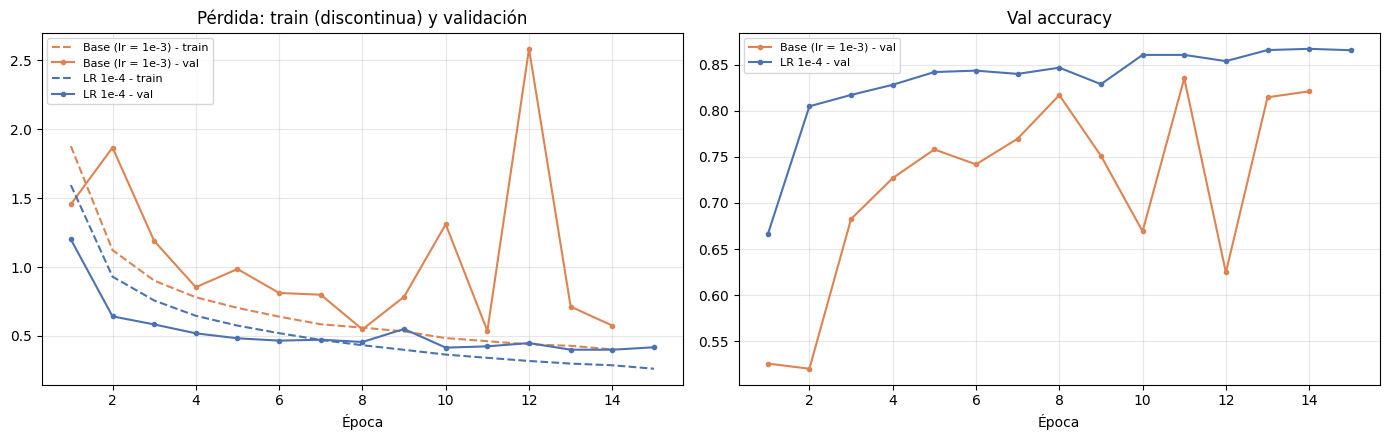

Base (lr = 1e-3)   | mejor val loss = 0.5361 (época 11) | oscilación (desde época 3) = 0.897 | mayor salto = +2.048
LR 1e-4            | mejor val loss = 0.3994 (época 14) | oscilación (desde época 3) = 0.053 | mayor salto = +0.094


In [ ]:
h_lr = historial("6. LR 1e-4")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for h, nombre, color in [(h_base, "Base (lr = 1e-3)", "#DD8452"), (h_lr, "LR 1e-4", "#4C72B0")]:
    e = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(e, h["loss"], ls="--", color=color, label=f"{nombre} - train")
    axes[0].plot(e, h["val_loss"], marker="o", ms=3, color=color, label=f"{nombre} - val")
    axes[1].plot(e, h["val_accuracy"], marker="o", ms=3, color=color, label=f"{nombre} - val")
axes[0].set_title("Pérdida: train (discontinua) y validación"); axes[1].set_title("Val accuracy")
for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

for h, nombre in [(h_base, "Base (lr = 1e-3)"), (h_lr, "LR 1e-4")]:
    vl = np.array(h["val_loss"])
    print(f"{nombre:<18} | mejor val loss = {vl.min():.4f} (época {vl.argmin() + 1}) | "
          f"oscilación (desde época 3) = {np.std(np.diff(vl[2:])):.3f} | mayor salto = +{np.diff(vl).max():.3f}")


Con `lr = 1e-4` el val loss desciende de forma casi monótona (oscilación de 0.053 frente a 0.897 del base, y mayor salto de +0.094 frente a +2.048), y la val accuracy se mantiene por encima de 0.80 desde la segunda época. Además, el F1-macro de validación sube de 0.758 a 0.809 y el de prueba de 0.736 a 0.800. Esto confirma que la inestabilidad del modelo base se debía a la tasa de aprendizaje y no a la arquitectura. Con `lr = 1e-4` sí aparece una brecha creciente entre train y validación hacia el final del entrenamiento (train loss 0.29 frente a val loss 0.40 en la época 14), que es la señal de sobreajuste a vigilar en la siguiente iteración.

## Comparación de resultados en validación

La tabla se ordena por F1-macro de validación. La columna `delta_F1_macro` es la diferencia frente al modelo base: positiva significa que la modificación mejora.

In [ ]:
tabla = pd.DataFrame([{
    "experimento": n,
    "cambio": r["descripcion"],
    "val_acc": r["val_acc"],
    "val_F1_macro": r["val_f1_macro"],
    "val_F1_weighted": r["val_f1_weighted"],
    "mejor_val_loss": r["val_loss"],
    "epocas": r["epocas"],
    "parametros": r["parametros"],
    "minutos": r["minutos"],
} for n, r in resultados.items()])

base_f1 = tabla.loc[tabla["experimento"] == "0. Base", "val_F1_macro"].iloc[0]
tabla["delta_F1_macro"] = tabla["val_F1_macro"] - base_f1
tabla = tabla.sort_values("val_F1_macro", ascending=False).reset_index(drop=True)

display(tabla.round({"val_acc": 4, "val_F1_macro": 4, "val_F1_weighted": 4,
                     "mejor_val_loss": 4, "delta_F1_macro": 4, "minutos": 1}))

,experimento,cambio,val_acc,val_F1_macro,val_F1_weighted,mejor_val_loss,epocas,parametros,minutos,delta_F1_macro
0,6. LR 1e-4,Learning rate 1e-3 -> 1e-4,0.8673,0.8094,0.8616,0.3994,15,1246312,4.4,0.0512
1,0. Base,Ninguno (referencia),0.8354,0.7581,0.8223,0.5361,14,1246312,4.2,0.0000
2,1. Class weights,class_weight='balanced',0.7691,0.7483,0.7809,0.7123,14,1246312,4.1,-0.0098
3,5. Bloque extra,Cuarto bloque convolucional de 256 filtros,0.8245,0.7451,0.8158,0.5184,12,887144,3.6,-0.0131
4,3. Dropout 0.6,Dropout 0.4 -> 0.6,0.8010,0.6560,0.7741,0.6027,11,1246312,3.3,-0.1021
5,2. Augmentation,"Rotación 15°, shifts 10% y zoom 10% (además de...",0.6920,0.5156,0.6564,0.9698,6,1246312,6.1,-0.2426
6,4. GAP,GlobalAveragePooling2D en lugar de Flatten,0.5414,0.3503,0.4940,1.4918,6,115816,1.8,-0.4079


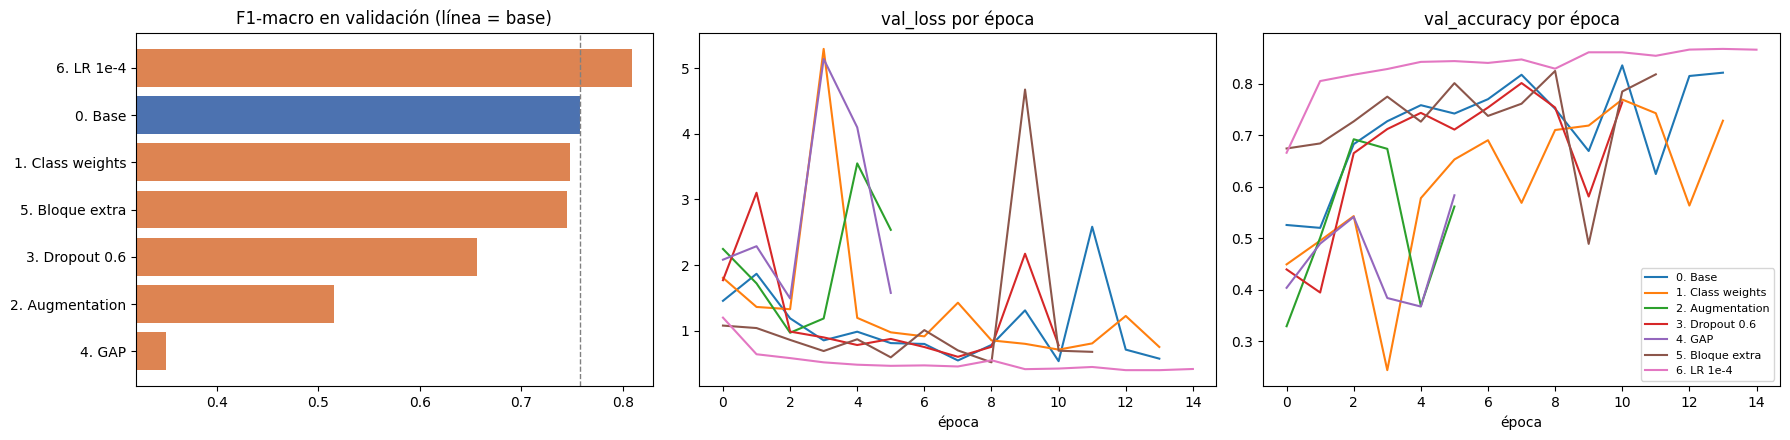

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) F1-macro por experimento
orden = tabla.sort_values("val_F1_macro")
colores = ["#4C72B0" if e.startswith("0.") else "#DD8452" for e in orden["experimento"]]
axes[0].barh(orden["experimento"], orden["val_F1_macro"], color=colores)
axes[0].axvline(base_f1, color="gray", linestyle="--", linewidth=1)
axes[0].set_title("F1-macro en validación (línea = base)")
axes[0].set_xlim(orden["val_F1_macro"].min() - 0.03, orden["val_F1_macro"].max() + 0.02)

# 2) y 3) curvas de validación por época
for nombre, r in resultados.items():
    axes[1].plot(r["historial"]["val_loss"], label=nombre)
    axes[2].plot(r["historial"]["val_accuracy"], label=nombre)
axes[1].set_title("val_loss por época"); axes[1].set_xlabel("época")
axes[2].set_title("val_accuracy por época"); axes[2].set_xlabel("época")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Evaluación final en prueba: modelo base vs. mejor modificación

El conjunto de prueba se usa una sola vez, solo para el modelo base y para el experimento con mayor F1-macro en validación.

In [ ]:
mejor = tabla.loc[tabla["experimento"] != "0. Base"].iloc[0]["experimento"]
print("Mejor modificación según F1-macro en validación:", mejor)

y_test = test_gen.classes
filas, preds_test = [], {}
for nombre in ["0. Base", mejor]:
    y_pred = resultados[nombre]["modelo"].predict(test_gen, verbose=0).argmax(axis=1)
    preds_test[nombre] = y_pred
    filas.append({
        "experimento": nombre,
        "test_acc": accuracy_score(y_test, y_pred),
        "test_F1_macro": f1_score(y_test, y_pred, average="macro"),
        "test_F1_weighted": f1_score(y_test, y_pred, average="weighted"),
    })
display(pd.DataFrame(filas).round(4))

Mejor modificación según F1-macro en validación: 6. LR 1e-4


,experimento,test_acc,test_F1_macro,test_F1_weighted
0,0. Base,0.8245,0.7360,0.8105
1,6. LR 1e-4,0.8592,0.7995,0.8529


In [ ]:
# F1 por clase: ¿en qué clases cambia el resultado respecto al base?
f1_base = f1_score(y_test, preds_test["0. Base"], average=None)
f1_mejor = f1_score(y_test, preds_test[mejor], average=None)

por_clase = pd.DataFrame({
    "clase": CLASES_ORDEN,
    "imgs_train": np.bincount(train_gen.classes, minlength=NUM_CLASSES),
    "F1_base": f1_base,
    f"F1_{mejor}": f1_mejor,
}).set_index("clase")
por_clase["delta"] = por_clase[f"F1_{mejor}"] - por_clase["F1_base"]

print("Clases que más mejoran:")
display(por_clase.sort_values("delta", ascending=False).head(8).round(3))
print("Clases que más empeoran:")
display(por_clase.sort_values("delta").head(8).round(3))

print(f"\nReporte por clase de: {mejor}")
print(classification_report(y_test, preds_test[mejor], target_names=CLASES_ORDEN, digits=3))

Clases que más mejoran:


,imgs_train,F1_base,F1_6. LR 1e-4,delta
clase,,,,
Innerwear Vests,169,0.348,0.762,0.414
Earrings,291,0.591,0.976,0.385
Dresses,307,0.391,0.724,0.333
Kurtis,164,0.000,0.275,0.275
Flats,350,0.050,0.283,0.233
Sweatshirts,198,0.427,0.588,0.162
Clutches,203,0.609,0.691,0.083
Sandals,627,0.731,0.812,0.081


Clases que más empeoran:


,imgs_train,F1_base,F1_6. LR 1e-4,delta
clase,,,,
Track Pants,213,0.901,0.833,-0.068
Sweaters,194,0.411,0.388,-0.023
Sunglasses,740,0.997,0.981,-0.015
Sarees,297,0.984,0.977,-0.007
Jeans,411,0.860,0.857,-0.003
Trousers,370,0.821,0.820,-0.001
Belts,568,0.988,0.988,0.000
Handbags,1230,0.927,0.930,0.003



Reporte por clase de: 6. LR 1e-4
                       precision    recall  f1-score   support

            Backpacks      0.909     0.926     0.917       108
                Belts      0.992     0.984     0.988       122
                  Bra      0.986     0.958     0.971        71
               Briefs      0.969     0.984     0.977       127
                 Caps      0.944     0.810     0.872        42
         Casual Shoes      0.777     0.801     0.789       427
             Clutches      0.737     0.651     0.691        43
            Deodorant      0.862     0.962     0.909        52
              Dresses      0.840     0.636     0.724        66
             Earrings      0.984     0.968     0.976        62
                Flats      0.421     0.213     0.283        75
           Flip Flops      0.792     0.826     0.809       138
         Formal Shoes      0.837     0.758     0.796        95
             Handbags      0.925     0.935     0.930       263
                Heel

## Diseño factorial: todas las combinaciones de modificaciones

En la sección anterior cada modificación se evaluó **por separado** (un cambio a la vez frente al base). Ese procedimiento supone que las técnicas actúan de forma independiente, pero no necesariamente es así: una técnica que por sí sola no ayuda puede complementarse con otra, y dos técnicas que ayudan por separado pueden anularse al combinarlas. Para evaluar esas **interacciones** se plantea un diseño factorial completo: se entrenan **todas las combinaciones posibles** de las cinco modificaciones.

| Factor | Nivel "off" (modelo base) | Nivel "on" |
|---|---|---|
| CW (class weights) | Sin ponderación | `class_weight='balanced'` |
| Aug (data augmentation) | Solo volteo horizontal | Volteo + rotación 15°, desplazamientos 10 % y zoom 10 % |
| Drop0.6 | Dropout 0.4 | Dropout 0.6 |
| GAP | `Flatten` | `GlobalAveragePooling2D` |
| Bloque | 3 bloques convolucionales | 4.º bloque de 256 filtros |

Esto da **2⁵ = 32 configuraciones**, que incluyen el modelo base (todo en "off") y las cinco modificaciones individuales.

**Configuración de entrenamiento común.** Todas las configuraciones usan `learning_rate = 1e-4`, porque el Experimento 6 mostró que con `1e-3` el entrenamiento es inestable (oscilación del val loss de 0.897 frente a 0.053) y esa inestabilidad perjudicaba más a las modificaciones que al base, lo que hacía injusta la comparación por separado. El resto se mantiene igual al base: batch size 64, Adam, máximo 15 épocas, `EarlyStopping` sobre `val_loss` con paciencia 3 y restauración de los mejores pesos, misma partición y misma semilla.

**Hipótesis:** si las técnicas interactúan, la mejor configuración del factorial será distinta de lo que sugiere la comparación por separado, y el efecto de cada técnica cambiará según las demás técnicas activas.

**Criterio de selección:** F1-macro en validación (métrica principal definida en la Unidad 1). El conjunto de prueba se usa una sola vez, al final, para el base y para la mejor configuración.

In [ ]:
# ================================================================
# CONFIGURACIÓN DEL DISEÑO FACTORIAL
# Es la única celda de esta sección que debería editarse.
# ================================================================
import gc, itertools, json, re, time
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1) Entrenamiento común a todas las configuraciones: lr = 1e-4 (justificado por el Experimento 6).
#    El resto de hiperparámetros toma los valores del modelo base (VALORES_BASE).
GRILLA = {
    "learning_rate": [1e-4],
}

# 2) Valores del modelo base para lo que no está en GRILLA
VALORES_BASE = {
    "learning_rate": 1e-3,
    "batch_size": BATCH_SIZE,
    "optimizador": "adam",
    "reduce_lr": False,
    "dense_units": 128,
    "dropout": 0.4,
}

# 3) Factores del diseño factorial (nivel "on" de cada modificación)
FACTORES = {
    "CW":      {"class_weight": True},
    "Aug":     {"augmentation": True},
    "Drop0.6": {"modelo": {"dropout": 0.6}},
    "GAP":     {"modelo": {"pooling": "gap"}},
    "Bloque":  {"modelo": {"filters": (32, 64, 128, 256)}},
}

def combinar_factores(activos):
    """Une las especificaciones de los factores activos en un solo experimento."""
    spec, modelo = {}, {}
    for f in activos:
        modelo.update(FACTORES[f].get("modelo", {}))
        for clave in ("class_weight", "augmentation"):
            if FACTORES[f].get(clave):
                spec[clave] = True
    if modelo:
        spec["modelo"] = modelo
    return spec

# Todas las combinaciones (2^5 = 32). La combinación sin factores es el modelo base.
EXPERIMENTOS_GRILLA = {}
FLAGS_EXP = {}
for flags in itertools.product([0, 1], repeat=len(FACTORES)):
    activos = [f for f, on in zip(FACTORES, flags) if on]
    nombre = "0. Base" if not activos else " + ".join(activos)
    EXPERIMENTOS_GRILLA[nombre] = combinar_factores(activos)
    FLAGS_EXP[nombre] = dict(zip(FACTORES, flags))

# 4) Ejecución
RESULTS_DIR = "factorial_resultados"   # carpeta de métricas, historiales y pesos
# Recomendado en Colab para no perder avances si la sesión se desconecta:
# from google.colab import drive
# drive.mount("/content/drive")
# RESULTS_DIR = "/content/drive/MyDrive/factorial_resultados"

USAR_CACHE_RAM = True   # carga las imágenes una sola vez en memoria (se desactiva sola si no hay RAM suficiente)
DETERMINISTA = False    # True = resultados repetibles en GPU, pero más lento (no se puede revertir en la sesión)
PRUEBA_RAPIDA = False   # True = prueba corta (pocos datos, 1 época) solo para verificar que el código funciona
VERBOSE_FIT = 2         # 2 = una línea por época | 0 = sin detalle

# 5) Confirmación del ranking con semillas adicionales (celda aparte, opcional)
SEMILLAS_EXTRA = [7, 2024]   # [] para omitir
TOP_A_CONFIRMAR = 2          # modificaciones (además del base) que se repiten con esas semillas

In [ ]:
# Validación de la configuración, lista de combinaciones y estimación de tiempo
requeridas = ["train_df", "val_df", "test_df", "IMG_SIZE", "BATCH_SIZE", "SEED",
              "MAX_EPOCHS", "PATIENCE", "build_variant_model", "train_datagen", "eval_datagen"]
faltan = [v for v in requeridas if v not in globals()]
if faltan:
    raise NameError(f"Faltan variables de celdas anteriores: {faltan}. Ejecute primero las celdas de carga "
                    "de datos, división, pipeline de imágenes, modelo base y funciones de apoyo.")

desconocidas = set(GRILLA) - set(VALORES_BASE)
if desconocidas:
    raise ValueError(f"Claves no soportadas en GRILLA: {desconocidas}. Permitidas: {list(VALORES_BASE)}")
if "0. Base" not in EXPERIMENTOS_GRILLA:
    raise ValueError("EXPERIMENTOS_GRILLA debe incluir '0. Base': es la referencia de la comparación.")
for nombre, spec in EXPERIMENTOS_GRILLA.items():
    choque = set(spec.get("modelo", {})) & set(GRILLA)
    if choque:
        raise ValueError(f"'{nombre}' fija {choque} y esa clave también está en GRILLA. Quite la clave de la "
                         "grilla o quite el experimento, para no mezclar dos cambios en el mismo factor.")

if DETERMINISTA:
    tf.config.experimental.enable_op_determinism()

ABREV = {"learning_rate": "lr", "batch_size": "bs", "optimizador": "opt",
         "reduce_lr": "rlr", "dense_units": "dense", "dropout": "drop"}

def etiqueta_combo(combo):
    """Texto corto que identifica una combinación, por ejemplo 'lr=0.0001 | bs=64'."""
    if not combo:
        return "valores base"
    return " | ".join(f"{ABREV[k]}={v:g}" if isinstance(v, float) else f"{ABREV[k]}={v}"
                      for k, v in combo.items())

COMBINACIONES = [dict(zip(GRILLA, valores)) for valores in itertools.product(*GRILLA.values())]
EXPERIMENTOS_G = list(EXPERIMENTOS_GRILLA)
MAX_EPOCHS_G, PATIENCE_G = MAX_EPOCHS, PATIENCE
SEMILLAS_G, TOP_G, DIR_G = list(SEMILLAS_EXTRA), TOP_A_CONFIRMAR, RESULTS_DIR
train_df_g = train_df

if PRUEBA_RAPIDA:
    COMBINACIONES, EXPERIMENTOS_G = COMBINACIONES[:2], EXPERIMENTOS_G[:2]
    MAX_EPOCHS_G, PATIENCE_G = 1, 1
    SEMILLAS_G, TOP_G = SEMILLAS_G[:1], min(TOP_G, 1)
    train_df_g = train_df.sample(n=min(2000, len(train_df)), random_state=SEED)
    DIR_G = RESULTS_DIR.rstrip("/") + "_prueba"
    print(f"MODO PRUEBA RÁPIDA: resultados en '{DIR_G}'. No usar estos números en el informe.\n")

n_runs = len(COMBINACIONES) * len(EXPERIMENTOS_G)
print(f"Tamaño de imagen: {IMG_SIZE} | máx. épocas: {MAX_EPOCHS_G} | paciencia: {PATIENCE_G}")
print(f"Combinaciones de hiperparámetros ({len(COMBINACIONES)}):")
for c in COMBINACIONES:
    print("   ", etiqueta_combo(c))
print(f"Experimentos ({len(EXPERIMENTOS_G)}): {EXPERIMENTOS_G}")
print(f"Entrenamientos de la grilla: {n_runs} "
      f"(+ hasta {(TOP_G + 1) * len(SEMILLAS_G)} de la confirmación con semillas)")

n_aug = sum(1 for e in EXPERIMENTOS_G if EXPERIMENTOS_GRILLA[e].get("augmentation"))
print(f"Configuraciones con augmentation: {n_aug} (son las más lentas, ~9 min cada una con caché)")
print(f"Estimación aproximada: ~{(n_aug * 9 + (len(EXPERIMENTOS_G) - n_aug) * 2) / 60:.1f} h. "
      "Se recomienda guardar RESULTS_DIR en Google Drive: si la sesión se cae, al volver a ejecutar "
      "se omiten las configuraciones ya entrenadas.")


Tamaño de imagen: (80, 60) | máx. épocas: 15 | paciencia: 3
Combinaciones de hiperparámetros (1):
    lr=0.0001
Experimentos (32): ['0. Base', 'Bloque', 'GAP', 'GAP + Bloque', 'Drop0.6', 'Drop0.6 + Bloque', 'Drop0.6 + GAP', 'Drop0.6 + GAP + Bloque', 'Aug', 'Aug + Bloque', 'Aug + GAP', 'Aug + GAP + Bloque', 'Aug + Drop0.6', 'Aug + Drop0.6 + Bloque', 'Aug + Drop0.6 + GAP', 'Aug + Drop0.6 + GAP + Bloque', 'CW', 'CW + Bloque', 'CW + GAP', 'CW + GAP + Bloque', 'CW + Drop0.6', 'CW + Drop0.6 + Bloque', 'CW + Drop0.6 + GAP', 'CW + Drop0.6 + GAP + Bloque', 'CW + Aug', 'CW + Aug + Bloque', 'CW + Aug + GAP', 'CW + Aug + GAP + Bloque', 'CW + Aug + Drop0.6', 'CW + Aug + Drop0.6 + Bloque', 'CW + Aug + Drop0.6 + GAP', 'CW + Aug + Drop0.6 + GAP + Bloque']
Entrenamientos de la grilla: 32 (+ hasta 6 de la confirmación con semillas)
Configuraciones con augmentation: 16 (son las más lentas, ~9 min cada una con caché)
Estimación aproximada: ~2.9 h. Se recomienda guardar RESULTS_DIR en Google Drive: si la s

In [ ]:
# Datos de la grilla: mismas imágenes, mismo tamaño, mismo orden de clases y mismos generadores
CLASES_G = sorted(train_df["articleType"].unique())
CLASE_A_IDX_G = {c: i for i, c in enumerate(CLASES_G)}
NUM_CLASSES_G = len(CLASES_G)
if "train_gen" in globals():
    assert CLASE_A_IDX_G == train_gen.class_indices, "El orden de clases no coincide con el generador original"

# Class weights: misma fórmula del experimento 1, sobre el conjunto de entrenamiento completo
y_train_completo = train_df["articleType"].map(CLASE_A_IDX_G).to_numpy()
CLASS_WEIGHTS_G = dict(enumerate(
    compute_class_weight("balanced", classes=np.arange(NUM_CLASSES_G), y=y_train_completo)))

# Augmentation: mismos parámetros del experimento 2 (el base sigue usando train_datagen)
AUG_DATAGEN_G = ImageDataGenerator(
    rescale=1./255, horizontal_flip=True, rotation_range=15,
    width_shift_range=0.1, height_shift_range=0.1, zoom_range=0.1, fill_mode="nearest",
)

SPLITS_G = {"train": train_df_g, "val": val_df, "test": test_df}
Y_G = {s: d["articleType"].map(CLASE_A_IDX_G).to_numpy() for s, d in SPLITS_G.items()}

# Caché en RAM (opcional): hace la misma lectura que flow_from_dataframe (RGB, redimensionado
# con interpolación "nearest"), pero una sola vez en lugar de en cada época.
def cargar_imagenes(dataframe):
    X = np.empty((len(dataframe), *IMG_SIZE, 3), dtype="float32")
    for i, ruta in enumerate(dataframe["image_path"]):
        img = tf.keras.utils.load_img(ruta, color_mode="rgb", target_size=IMG_SIZE, interpolation="nearest")
        X[i] = tf.keras.utils.img_to_array(img, dtype="float32")
    return X

clave_cache = (tuple(IMG_SIZE), tuple(len(d) for d in SPLITS_G.values()))
CACHE_ACTIVA = USAR_CACHE_RAM
if CACHE_ACTIVA and globals().get("_CLAVE_CACHE_G") != clave_cache:
    gb_necesarios = sum(len(d) for d in SPLITS_G.values()) * int(np.prod(IMG_SIZE)) * 3 * 4 / 1e9
    try:
        import psutil
        gb_disponibles = psutil.virtual_memory().available / 1e9
    except ImportError:
        gb_disponibles = float("inf")
    if gb_necesarios > 0.6 * gb_disponibles:
        print(f"RAM insuficiente para la caché ({gb_necesarios:.1f} GB de {gb_disponibles:.1f} GB "
              "disponibles): se leerá desde disco como en la sección anterior.")
        CACHE_ACTIVA = False
    else:
        t0 = time.time()
        CACHE_G = {s: cargar_imagenes(d) for s, d in SPLITS_G.items()}
        _CLAVE_CACHE_G = clave_cache
        print(f"Caché cargada: {gb_necesarios:.1f} GB en {(time.time() - t0) / 60:.1f} min")

def generador(datagen, split, batch_size, shuffle, seed=SEED):
    """Mismo ImageDataGenerator de siempre; solo cambia de dónde se leen las imágenes."""
    if CACHE_ACTIVA:
        Y = tf.keras.utils.to_categorical(Y_G[split], NUM_CLASSES_G)
        return datagen.flow(CACHE_G[split], Y, batch_size=int(batch_size), shuffle=shuffle, seed=seed)
    return datagen.flow_from_dataframe(
        dataframe=SPLITS_G[split], x_col="image_path", y_col="articleType", target_size=IMG_SIZE,
        batch_size=int(batch_size), class_mode="categorical", classes=CLASES_G, shuffle=shuffle, seed=seed)

VAL_GEN_G = generador(eval_datagen, "val", BATCH_SIZE, shuffle=False)
TEST_GEN_G = generador(eval_datagen, "test", BATCH_SIZE, shuffle=False)
print("Lectura de imágenes:", "caché en RAM" if CACHE_ACTIVA else "desde disco (flow_from_dataframe)")
print(f"Clases: {NUM_CLASSES_G} | train: {len(train_df_g)} | val: {len(val_df)} | test: {len(test_df)}")

Caché cargada: 2.3 GB en 0.3 min
Lectura de imágenes: caché en RAM
Clases: 40 | train: 27605 | val: 5916 | test: 5916


In [ ]:
# Función que entrena UNA combinación (experimento + hiperparámetros + semilla) y guarda todo en disco
os.makedirs(os.path.join(DIR_G, "pesos"), exist_ok=True)
RUTA_CSV_G = os.path.join(DIR_G, "grilla_resultados.csv")
RUTA_HIST_G = os.path.join(DIR_G, "grilla_historiales.json")

def cargar_resultados_grilla():
    if os.path.exists(RUTA_CSV_G):
        return pd.read_csv(RUTA_CSV_G).drop_duplicates("run_id", keep="last")
    return pd.DataFrame(columns=["run_id"])

def cargar_historiales_grilla():
    if os.path.exists(RUTA_HIST_G):
        with open(RUTA_HIST_G, encoding="utf-8") as f:
            return json.load(f)
    return {}

def crear_optimizador(nombre, lr):
    opciones = {
        "adam": lambda: tf.keras.optimizers.Adam(learning_rate=lr),
        "adamw": lambda: tf.keras.optimizers.AdamW(learning_rate=lr),
        "sgd": lambda: tf.keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
        "rmsprop": lambda: tf.keras.optimizers.RMSprop(learning_rate=lr),
    }
    if nombre not in opciones:
        raise ValueError(f"Optimizador no soportado: {nombre}. Opciones: {list(opciones)}")
    return opciones[nombre]()

def argumentos_modelo(experimento, hp):
    """Arquitectura = valores de la combinación + lo que fija el experimento."""
    kw = {"dense_units": int(hp["dense_units"]), "dropout": float(hp["dropout"])}
    kw.update(EXPERIMENTOS_GRILLA[experimento].get("modelo", {}))
    return kw

def entrenar_combinacion(experimento, combo, semilla=SEED):
    run_id = f"{experimento} || {etiqueta_combo(combo)} || semilla={semilla}"
    if run_id in set(cargar_resultados_grilla()["run_id"]):
        print("Ya existe, se omite:", run_id)
        return

    spec = EXPERIMENTOS_GRILLA[experimento]
    hp = {**VALORES_BASE, **combo}
    kw = argumentos_modelo(experimento, hp)

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(semilla)   # misma semilla para Python, NumPy y TensorFlow

    datagen = AUG_DATAGEN_G if spec.get("augmentation") else train_datagen
    gen_train = generador(datagen, "train", hp["batch_size"], shuffle=True, seed=semilla)

    m = build_variant_model((*IMG_SIZE, 3), NUM_CLASSES_G, **kw)
    m.compile(optimizer=crear_optimizador(hp["optimizador"], hp["learning_rate"]),
              loss="categorical_crossentropy", metrics=["accuracy"])
    es = EarlyStopping(monitor="val_loss", patience=PATIENCE_G, restore_best_weights=True)
    callbacks = [es]
    if hp["reduce_lr"]:
        callbacks.append(ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6))

    t0 = time.time()
    hist = m.fit(gen_train, validation_data=VAL_GEN_G, epochs=MAX_EPOCHS_G, callbacks=callbacks,
                 class_weight=CLASS_WEIGHTS_G if spec.get("class_weight") else None, verbose=VERBOSE_FIT)
    minutos = (time.time() - t0) / 60

    y_pred = m.predict(VAL_GEN_G, verbose=0).argmax(axis=1)
    val_loss = hist.history["val_loss"]
    slug = re.sub(r"[^A-Za-z0-9.=-]+", "_", run_id).strip("_")
    ruta_pesos = os.path.join(DIR_G, "pesos", f"{slug}.weights.h5")
    m.save_weights(ruta_pesos)

    efectivos = {k: hp[k] for k in VALORES_BASE}
    efectivos.update(dense_units=kw["dense_units"], dropout=kw["dropout"])
    fila = {
        "run_id": run_id, "experimento": experimento, "combinacion": etiqueta_combo(combo),
        "combo_json": json.dumps(combo), "semilla": semilla, **efectivos,
        "val_acc": accuracy_score(Y_G["val"], y_pred),
        "val_F1_macro": f1_score(Y_G["val"], y_pred, average="macro"),
        "val_F1_weighted": f1_score(Y_G["val"], y_pred, average="weighted"),
        "mejor_val_loss": float(np.min(val_loss)),
        "mejor_epoca": int(np.argmin(val_loss)) + 1,
        "epocas": len(val_loss),
        "paro_temprano": bool(es.stopped_epoch > 0),
        "parametros": m.count_params(),
        "minutos": minutos,
        "img_size": str(tuple(IMG_SIZE)), "max_epocas": MAX_EPOCHS_G, "paciencia": PATIENCE_G,
        "cache_ram": CACHE_ACTIVA, "ruta_pesos": ruta_pesos,
    }
    pd.DataFrame([fila]).to_csv(RUTA_CSV_G, mode="a", header=not os.path.exists(RUTA_CSV_G), index=False)

    historiales = cargar_historiales_grilla()
    historiales[run_id] = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    with open(RUTA_HIST_G, "w", encoding="utf-8") as f:
        json.dump(historiales, f)

    print(f">>> {run_id}: val_acc={fila['val_acc']:.4f} | val_F1-macro={fila['val_F1_macro']:.4f} "
          f"| épocas={fila['epocas']} (mejor: {fila['mejor_epoca']}) | {minutos:.1f} min")
    del m, gen_train
    gc.collect()

print("Resultados en:", os.path.abspath(DIR_G))
print("Entrenamientos ya guardados en esa carpeta:", len(cargar_resultados_grilla()))

Resultados en: /content/factorial_resultados
Entrenamientos ya guardados en esa carpeta: 0


### Ejecución del diseño factorial

El ciclo entrena las 32 configuraciones con la misma semilla. Cada resultado se guarda en disco apenas termina.

In [ ]:
t_inicio = time.time()
total = len(COMBINACIONES) * len(EXPERIMENTOS_G)
k = 0
for combo in COMBINACIONES:
    for nombre in EXPERIMENTOS_G:
        k += 1
        print(f"\n===== [{k}/{total}] {nombre} | {etiqueta_combo(combo)} =====")
        entrenar_combinacion(nombre, combo, SEED)
print(f"\nGrilla terminada. Tiempo de esta ejecución: {(time.time() - t_inicio) / 60:.1f} min")


===== [1/32] 0. Base | lr=0.0001 =====
Epoch 1/15
432/432 - 17s - 38ms/step - accuracy: 0.5590 - loss: 1.6375 - val_accuracy: 0.5911 - val_loss: 1.5641
Epoch 2/15
432/432 - 7s - 16ms/step - accuracy: 0.7303 - loss: 0.9324 - val_accuracy: 0.8031 - val_loss: 0.6479
Epoch 3/15
432/432 - 7s - 17ms/step - accuracy: 0.7776 - loss: 0.7365 - val_accuracy: 0.8078 - val_loss: 0.5908
Epoch 4/15
432/432 - 7s - 16ms/step - accuracy: 0.8062 - loss: 0.6266 - val_accuracy: 0.8349 - val_loss: 0.5350
Epoch 5/15
432/432 - 7s - 16ms/step - accuracy: 0.8238 - loss: 0.5592 - val_accuracy: 0.8450 - val_loss: 0.4820
Epoch 6/15
432/432 - 7s - 15ms/step - accuracy: 0.8413 - loss: 0.4933 - val_accuracy: 0.8492 - val_loss: 0.4741
Epoch 7/15
432/432 - 7s - 16ms/step - accuracy: 0.8519 - loss: 0.4460 - val_accuracy: 0.8536 - val_loss: 0.4642
Epoch 8/15
432/432 - 7s - 15ms/step - accuracy: 0.8650 - loss: 0.4035 - val_accuracy: 0.8345 - val_loss: 0.5202
Epoch 9/15
432/432 - 7s - 16ms/step - accuracy: 0.8736 - loss: 

### Resultados del diseño factorial en validación

Se presentan cuatro tablas:

- **Diez mejores configuraciones** según F1-macro en validación.
- **Efecto de cada técnica:** el *efecto por separado* es el cambio en F1-macro al agregar solo esa técnica al base (lo que mide la comparación uno a uno); el *efecto promedio* es la diferencia entre el F1-macro promedio de las 16 configuraciones con la técnica y las 16 sin ella. Si ambos efectos difieren mucho, el efecto de la técnica depende de las demás, es decir, hay interacción.
- **Interacciones entre pares:** para cada par de técnicas A y B, cuánto cambia el efecto de A cuando B está activa (promedio sobre las demás técnicas). Un valor positivo indica que se complementan; uno negativo, que se estorban.
- **Posición del "combinado ingenuo":** la configuración que junta todas las técnicas que por separado mejoraron al base, para comprobar si sumar lo que funciona por separado da la mejor combinación.

In [ ]:
grilla = cargar_resultados_grilla()
g = grilla[(grilla["semilla"] == SEED) & (grilla["experimento"].isin(EXPERIMENTOS_G))].copy()
faltan_exp = [e for e in EXPERIMENTOS_G if e not in set(g["experimento"])]
if faltan_exp:
    print(f"Faltan {len(faltan_exp)} configuraciones por entrenar; el análisis usa solo las completas.")
    if len(faltan_exp) == len(EXPERIMENTOS_G):
        raise RuntimeError("Todavía no hay resultados del diseño factorial.")

g = g.drop_duplicates("experimento", keep="last").set_index("experimento")
for f in FACTORES:
    g[f] = [FLAGS_EXP[e][f] for e in g.index]
g["n_tecnicas"] = g[list(FACTORES)].sum(axis=1)

# Tabla usada por las celdas siguientes (semillas, prueba y matriz de confusión)
mejores_g = g[["combinacion", "val_acc", "val_F1_macro", "val_F1_weighted", "mejor_val_loss", "epocas",
               "mejor_epoca", "paro_temprano", "parametros", "minutos", "run_id", "ruta_pesos",
               "combo_json"]].sort_values("val_F1_macro", ascending=False)
base_f1_g = mejores_g.loc["0. Base", "val_F1_macro"]
mejores_g["delta_vs_base"] = mejores_g["val_F1_macro"] - base_f1_g
mejores_g["posicion"] = np.arange(1, len(mejores_g) + 1)

cols_top = ["posicion", "val_acc", "val_F1_macro", "val_F1_weighted", "mejor_val_loss",
            "mejor_epoca", "epocas", "parametros", "minutos", "delta_vs_base"]
print(f"1) Diez mejores configuraciones (validación). Base: F1-macro = {base_f1_g:.4f}, "
      f"posición {mejores_g.loc['0. Base', 'posicion']} de {len(mejores_g)}")
display(mejores_g[cols_top].head(10).round(4))

# 2) Efecto por separado vs. efecto promedio de cada técnica
filas_ef = []
for f in FACTORES:
    solo = f if f in g.index else None
    filas_ef.append({
        "tecnica": f,
        "efecto_por_separado": (g.loc[solo, "val_F1_macro"] - base_f1_g) if solo else np.nan,
        "efecto_promedio": g.loc[g[f] == 1, "val_F1_macro"].mean() - g.loc[g[f] == 0, "val_F1_macro"].mean(),
        "F1_prom_con": g.loc[g[f] == 1, "val_F1_macro"].mean(),
        "F1_prom_sin": g.loc[g[f] == 0, "val_F1_macro"].mean(),
    })
efectos_g = pd.DataFrame(filas_ef).set_index("tecnica")
efectos_g["diferencia (interacción)"] = efectos_g["efecto_promedio"] - efectos_g["efecto_por_separado"]
print("2) Efecto de cada técnica sobre el F1-macro de validación (positivo = mejora)")
display(efectos_g.round(4))

# 3) Interacción entre pares: efecto de A con B activa menos efecto de A con B inactiva
nombres_f = list(FACTORES)
inter_g = pd.DataFrame(np.nan, index=nombres_f, columns=nombres_f)
for a_f, b_f in itertools.combinations(nombres_f, 2):
    ef_a_con_b = g.loc[(g[a_f] == 1) & (g[b_f] == 1), "val_F1_macro"].mean() - \
                 g.loc[(g[a_f] == 0) & (g[b_f] == 1), "val_F1_macro"].mean()
    ef_a_sin_b = g.loc[(g[a_f] == 1) & (g[b_f] == 0), "val_F1_macro"].mean() - \
                 g.loc[(g[a_f] == 0) & (g[b_f] == 0), "val_F1_macro"].mean()
    inter_g.loc[a_f, b_f] = inter_g.loc[b_f, a_f] = (ef_a_con_b - ef_a_sin_b) / 2
print("3) Interacción entre pares de técnicas (positivo = se complementan, negativo = se estorban)")
display(inter_g.round(4))

# 4) "Combinado ingenuo": todas las técnicas que por separado mejoraron al base
utiles = [f for f in nombres_f if efectos_g.loc[f, "efecto_por_separado"] > 0]
nombre_ingenuo = " + ".join(utiles) if utiles else "0. Base"
print(f"4) Técnicas que por separado mejoran al base: {utiles if utiles else 'ninguna'}")
if nombre_ingenuo in mejores_g.index:
    fila = mejores_g.loc[nombre_ingenuo]
    print(f"   Combinado ingenuo '{nombre_ingenuo}': F1-macro = {fila['val_F1_macro']:.4f}, "
          f"posición {int(fila['posicion'])} de {len(mejores_g)}")
print(f"   Mejor configuración del factorial: '{mejores_g.index[0]}' "
      f"(F1-macro = {mejores_g['val_F1_macro'].iloc[0]:.4f})")

sin_paro = mejores_g[mejores_g["paro_temprano"].astype(str) == "False"]
if len(sin_paro):
    print(f"\nConfiguraciones que llegaron a {MAX_EPOCHS_G} épocas sin activar EarlyStopping "
          "(podrían mejorar con más épocas):")
    display(sin_paro[["val_F1_macro", "mejor_epoca", "posicion"]].round(4))

mejores_g.to_csv(os.path.join(DIR_G, "tabla_factorial_completa.csv"))
efectos_g.to_csv(os.path.join(DIR_G, "tabla_efectos_por_tecnica.csv"))
inter_g.to_csv(os.path.join(DIR_G, "tabla_interacciones_pares.csv"))


1) Diez mejores configuraciones (validación). Base: F1-macro = 0.8165, posición 1 de 32


,posicion,val_acc,val_F1_macro,val_F1_weighted,mejor_val_loss,mejor_epoca,epocas,parametros,minutos,delta_vs_base
experimento,,,,,,,,,,
0. Base,1,0.8648,0.8165,0.8607,0.4204,13,15,1246312,1.8917,0.0000
Bloque,2,0.8675,0.8151,0.8644,0.4197,15,15,887144,2.1408,-0.0014
CW,3,0.8311,0.8062,0.8400,0.5120,15,15,1246312,2.4045,-0.0103
CW + Drop0.6 + Bloque,4,0.8225,0.8052,0.8285,0.5268,15,15,887144,2.8198,-0.0113
Drop0.6,5,0.8612,0.8022,0.8552,0.4134,15,15,1246312,1.9459,-0.0143
CW + Drop0.6,6,0.8257,0.8013,0.8334,0.5194,15,15,1246312,2.1916,-0.0152
CW + Bloque,7,0.8291,0.7990,0.8358,0.5166,13,15,887144,2.6354,-0.0175
Drop0.6 + Bloque,8,0.8555,0.7890,0.8476,0.4389,10,13,887144,1.8654,-0.0275
CW + Drop0.6 + GAP + Bloque,9,0.7857,0.7647,0.7949,0.6350,15,15,428392,2.5668,-0.0518


2) Efecto de cada técnica sobre el F1-macro de validación (positivo = mejora)


,efecto_por_separado,efecto_promedio,F1_prom_con,F1_prom_sin,diferencia (interacción)
tecnica,,,,,
CW,-0.0103,0.0211,0.6883,0.6672,0.0314
Aug,-0.0771,-0.0612,0.6472,0.7083,0.0160
Drop0.6,-0.0143,-0.0072,0.6742,0.6814,0.0071
GAP,-0.4716,-0.1607,0.5974,0.7581,0.3109
Bloque,-0.0014,0.1065,0.7310,0.6245,0.1079


3) Interacción entre pares de técnicas (positivo = se complementan, negativo = se estorban)


,CW,Aug,Drop0.6,GAP,Bloque
CW,NaN,-0.0062,-0.0188,0.0236,-0.0026
Aug,-0.0062,NaN,-0.0093,0.0312,-0.0166
Drop0.6,-0.0188,-0.0093,NaN,0.0121,-0.0020
GAP,0.0236,0.0312,0.0121,NaN,0.1053
Bloque,-0.0026,-0.0166,-0.0020,0.1053,NaN


4) Técnicas que por separado mejoran al base: ninguna
   Combinado ingenuo '0. Base': F1-macro = 0.8165, posición 1 de 32
   Mejor configuración del factorial: '0. Base' (F1-macro = 0.8165)

Configuraciones que llegaron a 15 épocas sin activar EarlyStopping (podrían mejorar con más épocas):


,val_F1_macro,mejor_epoca,posicion
experimento,,,
0. Base,0.8165,13,1
Bloque,0.8151,15,2
CW,0.8062,15,3
CW + Drop0.6 + Bloque,0.8052,15,4
Drop0.6,0.8022,15,5
CW + Drop0.6,0.8013,15,6
CW + Bloque,0.7990,13,7
CW + Drop0.6 + GAP + Bloque,0.7647,15,9
Aug,0.7394,15,11


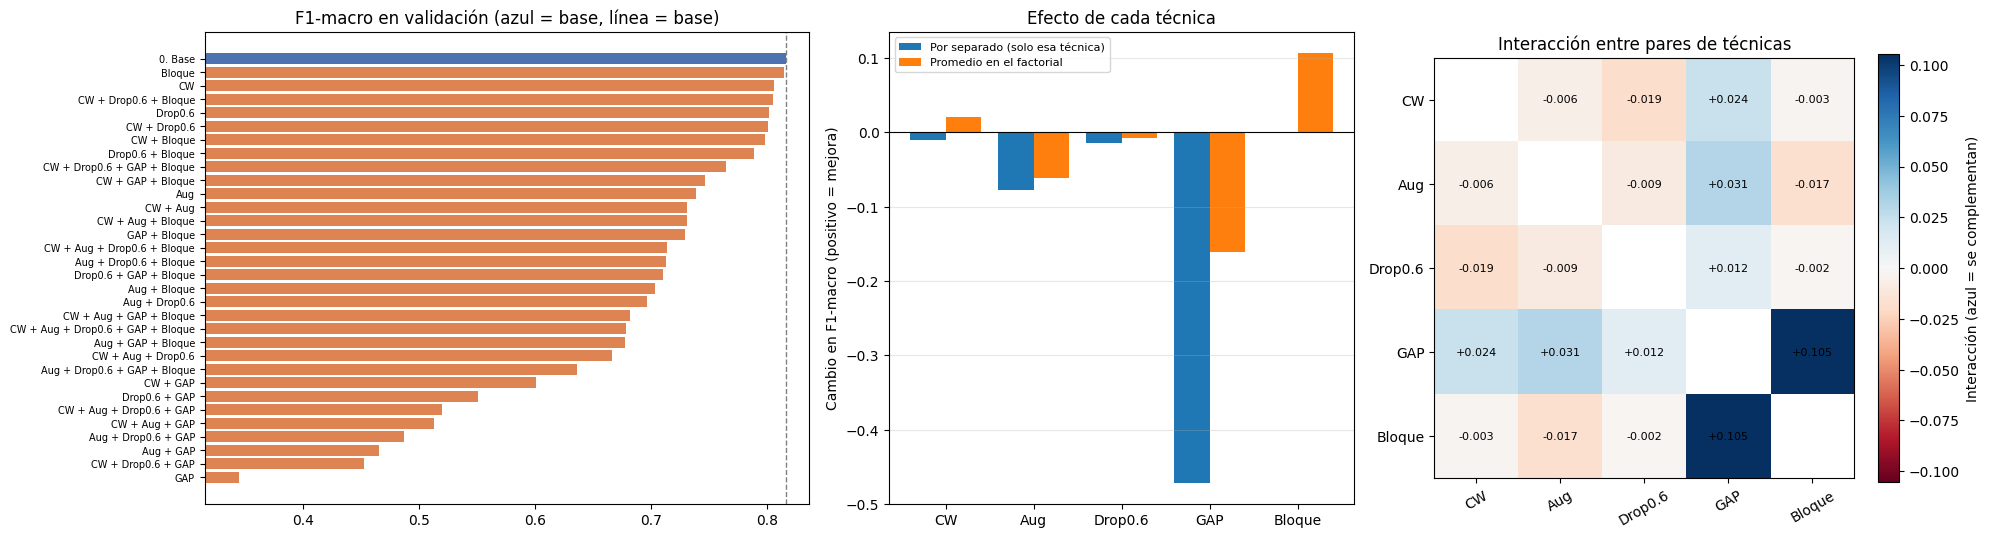

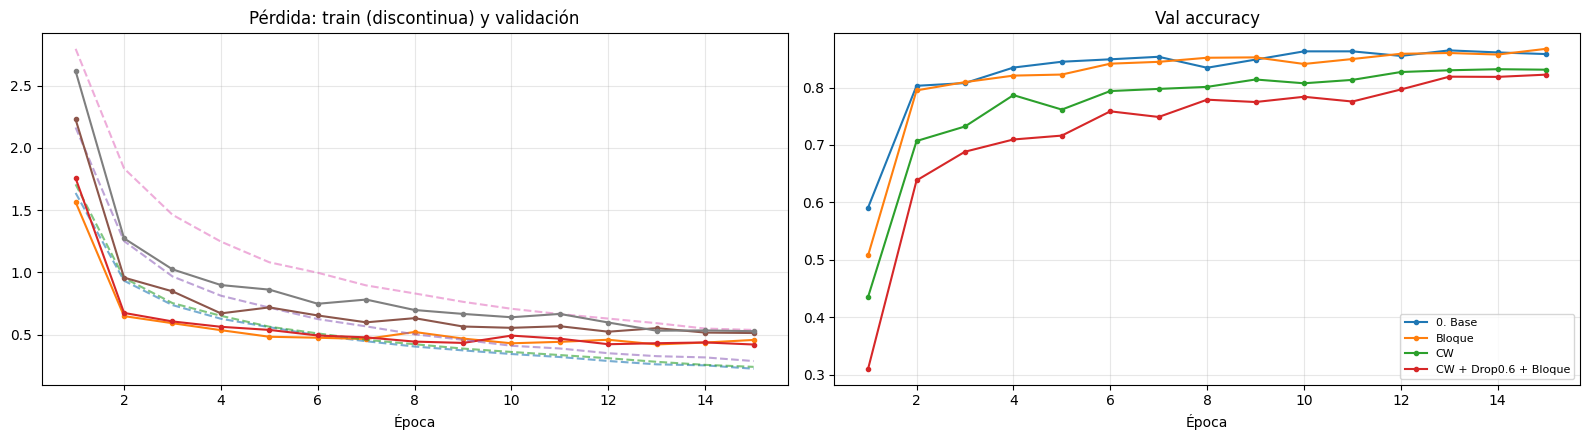

In [ ]:
# Figuras del diseño factorial
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})

# a) F1-macro de las 32 configuraciones
orden = mejores_g.sort_values("val_F1_macro")
colores = ["#4C72B0" if e == "0. Base" else "#DD8452" for e in orden.index]
axes[0].barh(orden.index, orden["val_F1_macro"], color=colores)
axes[0].axvline(base_f1_g, color="gray", ls="--", lw=1)
axes[0].set_xlim(orden["val_F1_macro"].min() - 0.03, orden["val_F1_macro"].max() + 0.02)
axes[0].tick_params(axis="y", labelsize=7)
axes[0].set_title("F1-macro en validación (azul = base, línea = base)")

# b) Efecto por separado vs. efecto promedio
x = np.arange(len(efectos_g))
axes[1].bar(x - 0.2, efectos_g["efecto_por_separado"], 0.4, label="Por separado (solo esa técnica)")
axes[1].bar(x + 0.2, efectos_g["efecto_promedio"], 0.4, label="Promedio en el factorial")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(x); axes[1].set_xticklabels(efectos_g.index)
axes[1].set_ylabel("Cambio en F1-macro (positivo = mejora)")
axes[1].set_title("Efecto de cada técnica"); axes[1].legend(fontsize=8); axes[1].grid(axis="y", alpha=0.3)

# c) Interacciones entre pares
lim = np.nanmax(np.abs(inter_g.to_numpy()))
im = axes[2].imshow(inter_g.to_numpy(dtype=float), cmap="RdBu", vmin=-lim, vmax=lim)
axes[2].set_xticks(range(len(inter_g))); axes[2].set_xticklabels(inter_g.columns, rotation=30)
axes[2].set_yticks(range(len(inter_g))); axes[2].set_yticklabels(inter_g.index)
for i in range(len(inter_g)):
    for j in range(len(inter_g)):
        if i != j:
            axes[2].text(j, i, f"{inter_g.iloc[i, j]:+.3f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=axes[2], fraction=0.046, label="Interacción (azul = se complementan)")
axes[2].set_title("Interacción entre pares de técnicas")
plt.tight_layout(); plt.show()

# d) Curvas de validación: base y las tres mejores configuraciones
historiales_g = cargar_historiales_grilla()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for exp in ["0. Base"] + [e for e in mejores_g.index if e != "0. Base"][:3]:
    h = historiales_g[mejores_g.loc[exp, "run_id"]]
    e = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(e, h["loss"], ls="--", alpha=0.6)
    axes[0].plot(e, h["val_loss"], marker="o", ms=3, label=exp)
    axes[1].plot(e, h["val_accuracy"], marker="o", ms=3, label=exp)
axes[0].set_title("Pérdida: train (discontinua) y validación"); axes[1].set_title("Val accuracy")
for ax in axes:
    ax.set_xlabel("Época"); ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


### Confirmación con semillas adicionales

Cada configuración del factorial se entrenó una sola vez (semilla 42). Para saber si las diferencias entre los primeros lugares son reales o se deben al azar del entrenamiento, se repite la mejor combinación del base y de las mejores modificaciones con otras semillas (`SEMILLAS_EXTRA`). Si la diferencia entre dos experimentos es menor que la variación entre semillas, no se puede afirmar que uno sea mejor que el otro.

In [ ]:
confirmacion_g = None
if not SEMILLAS_G or TOP_G <= 0:
    print("Confirmación omitida (SEMILLAS_EXTRA vacío o TOP_A_CONFIRMAR = 0).")
else:
    a_confirmar = ["0. Base"] + [e for e in mejores_g.index if e != "0. Base"][:TOP_G]
    for exp in a_confirmar:
        combo = json.loads(mejores_g.loc[exp, "combo_json"])
        for s in SEMILLAS_G:
            print(f"\n===== Confirmación: {exp} | {etiqueta_combo(combo)} | semilla {s} =====")
            entrenar_combinacion(exp, combo, s)

    todas = cargar_resultados_grilla()
    filas = []
    for exp in a_confirmar:
        comb = mejores_g.loc[exp, "combinacion"]
        sel = todas[(todas["experimento"] == exp) & (todas["combinacion"] == comb)
                    & (todas["semilla"].isin([SEED] + SEMILLAS_G))]
        filas.append({"experimento": exp, "combinacion": comb, "corridas": len(sel),
                      "F1_macro_promedio": sel["val_F1_macro"].mean(),
                      "F1_macro_desv": sel["val_F1_macro"].std(),
                      "F1_macro_min": sel["val_F1_macro"].min(),
                      "F1_macro_max": sel["val_F1_macro"].max(),
                      "val_acc_promedio": sel["val_acc"].mean()})
    confirmacion_g = pd.DataFrame(filas).set_index("experimento").sort_values("F1_macro_promedio", ascending=False)
    print(f"\nResultados con semillas {[SEED] + SEMILLAS_G} (validación)")
    display(confirmacion_g.round(4))
    confirmacion_g.to_csv(os.path.join(DIR_G, "tabla_confirmacion_semillas.csv"))


===== Confirmación: 0. Base | lr=0.0001 | semilla 7 =====
Epoch 1/15
432/432 - 17s - 40ms/step - accuracy: 0.5829 - loss: 1.5430 - val_accuracy: 0.6976 - val_loss: 1.1497
Epoch 2/15
432/432 - 7s - 16ms/step - accuracy: 0.7304 - loss: 0.9073 - val_accuracy: 0.8139 - val_loss: 0.6119
Epoch 3/15
432/432 - 7s - 16ms/step - accuracy: 0.7761 - loss: 0.7386 - val_accuracy: 0.8173 - val_loss: 0.5734
Epoch 4/15
432/432 - 7s - 16ms/step - accuracy: 0.8055 - loss: 0.6242 - val_accuracy: 0.8310 - val_loss: 0.5203
Epoch 5/15
432/432 - 7s - 16ms/step - accuracy: 0.8221 - loss: 0.5610 - val_accuracy: 0.8435 - val_loss: 0.4786
Epoch 6/15
432/432 - 7s - 17ms/step - accuracy: 0.8362 - loss: 0.5063 - val_accuracy: 0.8337 - val_loss: 0.5235
Epoch 7/15
432/432 - 7s - 15ms/step - accuracy: 0.8481 - loss: 0.4604 - val_accuracy: 0.8509 - val_loss: 0.4508
Epoch 8/15
432/432 - 7s - 16ms/step - accuracy: 0.8582 - loss: 0.4211 - val_accuracy: 0.8538 - val_loss: 0.4487
Epoch 9/15
432/432 - 7s - 15ms/step - accura

,combinacion,corridas,F1_macro_promedio,F1_macro_desv,F1_macro_min,F1_macro_max,val_acc_promedio
experimento,,,,,,,
0. Base,lr=0.0001,3,0.8168,0.0055,0.8114,0.8225,0.8664
Bloque,lr=0.0001,3,0.8093,0.0110,0.7966,0.8161,0.8627
CW,lr=0.0001,3,0.8026,0.0075,0.7940,0.8077,0.8311


### Evaluación final en prueba (diseño factorial)

La selección se hace solo con validación: la mejor configuración es la de mayor F1-macro promedio en la confirmación con semillas (o, si la confirmación se omitió, la de mayor F1-macro en el factorial). En prueba se evalúan únicamente el modelo base (con `lr = 1e-4`) y esa configuración, usando los pesos guardados del entrenamiento con semilla 42.

In [ ]:
orden_g = (confirmacion_g["F1_macro_promedio"] if confirmacion_g is not None else mejores_g["val_F1_macro"])
mejor_mod_g = orden_g.drop(index="0. Base").idxmax()
print("Mejor modificación según validación:", mejor_mod_g, "|", mejores_g.loc[mejor_mod_g, "combinacion"])
print("Base con su mejor combinación:", mejores_g.loc["0. Base", "combinacion"])
if orden_g.idxmax() == "0. Base":
    print("Nota: en validación, el base con su mejor combinación supera a todas las modificaciones.")

def predecir_prueba(experimento):
    fila = mejores_g.loc[experimento]
    hp = {**VALORES_BASE, **json.loads(fila["combo_json"])}
    tf.keras.backend.clear_session()
    m = build_variant_model((*IMG_SIZE, 3), NUM_CLASSES_G, **argumentos_modelo(experimento, hp))
    m.load_weights(fila["ruta_pesos"])
    return m.predict(TEST_GEN_G, verbose=0).argmax(axis=1)

preds_test_g = {e: predecir_prueba(e) for e in ["0. Base", mejor_mod_g]}
y_test_g = Y_G["test"]
tabla_test_g = pd.DataFrame([{
    "experimento": e, "combinacion": mejores_g.loc[e, "combinacion"],
    "test_acc": accuracy_score(y_test_g, p),
    "test_F1_macro": f1_score(y_test_g, p, average="macro"),
    "test_F1_weighted": f1_score(y_test_g, p, average="weighted"),
} for e, p in preds_test_g.items()])
display(tabla_test_g.round(4))

etiquetas_idx = list(range(NUM_CLASSES_G))
por_clase_g = pd.DataFrame({
    "clase": CLASES_G,
    "imgs_train": np.bincount(y_train_completo, minlength=NUM_CLASSES_G),
    "F1_base": f1_score(y_test_g, preds_test_g["0. Base"], average=None, labels=etiquetas_idx, zero_division=0),
    "F1_mejor": f1_score(y_test_g, preds_test_g[mejor_mod_g], average=None, labels=etiquetas_idx, zero_division=0),
}).set_index("clase")
por_clase_g["delta"] = por_clase_g["F1_mejor"] - por_clase_g["F1_base"]
print(f"Clases que más mejoran ({mejor_mod_g} vs. 0. Base):")
display(por_clase_g.sort_values("delta", ascending=False).head(8).round(3))
print("Clases que más empeoran:")
display(por_clase_g.sort_values("delta").head(8).round(3))
print(f"\nReporte por clase de: {mejor_mod_g} ({mejores_g.loc[mejor_mod_g, 'combinacion']})")
print(classification_report(y_test_g, preds_test_g[mejor_mod_g], labels=etiquetas_idx,
                            target_names=CLASES_G, digits=3, zero_division=0))

tabla_test_g.to_csv(os.path.join(DIR_G, "tabla_prueba.csv"), index=False)
por_clase_g.to_csv(os.path.join(DIR_G, "tabla_f1_por_clase_prueba.csv"))

Mejor modificación según validación: Bloque | lr=0.0001
Base con su mejor combinación: lr=0.0001
Nota: en validación, el base con su mejor combinación supera a todas las modificaciones.


,experimento,combinacion,test_acc,test_F1_macro,test_F1_weighted
0,0. Base,lr=0.0001,0.8578,0.8005,0.8528
1,Bloque,lr=0.0001,0.8621,0.8075,0.8587


Clases que más mejoran (Bloque vs. 0. Base):


,imgs_train,F1_base,F1_mejor,delta
clase,,,,
Kurtis,164,0.196,0.312,0.116
Flats,350,0.319,0.412,0.093
Sweatshirts,198,0.471,0.525,0.054
Sandals,627,0.783,0.819,0.036
Tops,1166,0.628,0.657,0.029
Perfume and Body Mist,427,0.863,0.891,0.028
Shorts,349,0.886,0.910,0.024
Earrings,291,0.961,0.984,0.023


Clases que más empeoran:


,imgs_train,F1_base,F1_mejor,delta
clase,,,,
Heels,924,0.800,0.758,-0.042
Sweaters,194,0.471,0.429,-0.042
Dresses,307,0.781,0.741,-0.040
Caps,197,0.840,0.821,-0.019
Trousers,370,0.868,0.850,-0.018
Innerwear Vests,169,0.735,0.724,-0.011
Wallets,654,0.905,0.895,-0.011
Tunics,160,0.218,0.208,-0.010



Reporte por clase de: Bloque (lr=0.0001)
                       precision    recall  f1-score   support

            Backpacks      0.943     0.926     0.935       108
                Belts      0.992     0.992     0.992       122
                  Bra      1.000     0.986     0.993        71
               Briefs      0.984     0.961     0.972       127
                 Caps      0.889     0.762     0.821        42
         Casual Shoes      0.762     0.838     0.798       427
             Clutches      0.758     0.581     0.658        43
            Deodorant      0.913     0.808     0.857        52
              Dresses      0.860     0.652     0.741        66
             Earrings      0.969     1.000     0.984        62
                Flats      0.368     0.467     0.412        75
           Flip Flops      0.862     0.768     0.812       138
         Formal Shoes      0.862     0.789     0.824        95
             Handbags      0.899     0.947     0.922       263
            

### Matriz de confusión en prueba

La tabla de F1 por clase indica *qué* clases fallan, pero no *con cuáles* se confunden. La matriz de confusión responde esa pregunta: cada fila es la clase real y cada columna la clase predicha, de modo que la diagonal son los aciertos y el resto de la fila muestra hacia dónde se va el error. Se calcula sobre el conjunto de prueba para el modelo base y para la mejor modificación, con las mismas predicciones ya obtenidas en la celda anterior.


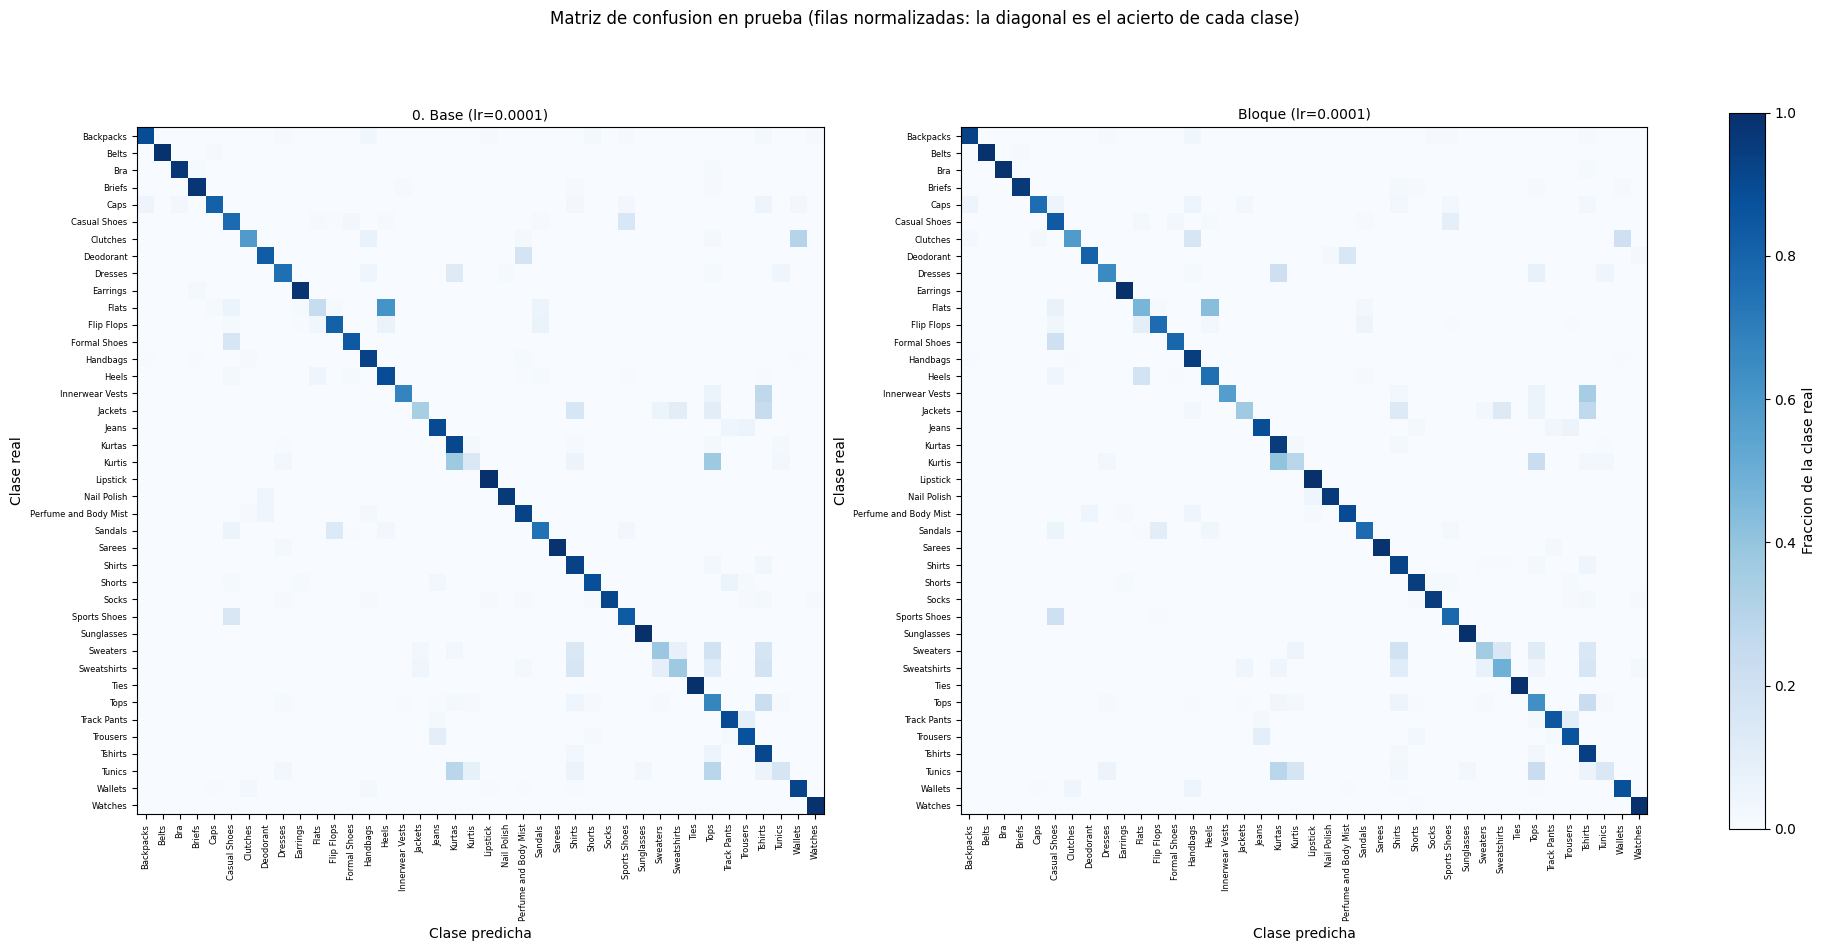

In [ ]:
# Matriz de confusion en prueba: modelo base vs. mejor modificacion
from sklearn.metrics import confusion_matrix

ETIQUETAS_IDX = list(range(NUM_CLASSES_G))

def matriz_confusion(y_true, y_pred):
    """Devuelve la matriz en conteos y la misma matriz con cada fila normalizada,
    es decir, que fraccion de cada clase real fue predicha en cada clase."""
    cm = confusion_matrix(y_true, y_pred, labels=ETIQUETAS_IDX)
    totales = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, totales, out=np.zeros(cm.shape, dtype=float), where=totales > 0)
    return cm, cm_norm

matrices = {}
fig, axes = plt.subplots(1, 2, figsize=(21, 9.5))
for ax, nombre in zip(axes, ["0. Base", mejor_mod_g]):
    cm, cm_norm = matriz_confusion(y_test_g, preds_test_g[nombre])
    matrices[nombre] = (cm, cm_norm)
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(ETIQUETAS_IDX); ax.set_xticklabels(CLASES_G, rotation=90, fontsize=6)
    ax.set_yticks(ETIQUETAS_IDX); ax.set_yticklabels(CLASES_G, fontsize=6)
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
    ax.set_title(f"{nombre} ({mejores_g.loc[nombre, 'combinacion']})", fontsize=10)
fig.colorbar(im, ax=axes, fraction=0.022, label="Fraccion de la clase real")
fig.suptitle("Matriz de confusion en prueba (filas normalizadas: la diagonal es el acierto de cada clase)")
plt.show()

In [ ]:
# Principales confusiones del modelo final y resumen por clase
cm_mejor, cm_mejor_norm = matrices[mejor_mod_g]

pares = [{
    "clase_real": CLASES_G[i],
    "clase_predicha": CLASES_G[j],
    "imagenes": int(cm_mejor[i, j]),
    "pct_de_la_clase_real": round(cm_mejor_norm[i, j] * 100, 1),
} for i in ETIQUETAS_IDX for j in ETIQUETAS_IDX if i != j and cm_mejor[i, j] > 0]

confusiones = (pd.DataFrame(pares)
               .sort_values("pct_de_la_clase_real", ascending=False)
               .reset_index(drop=True))
print(f"Principales confusiones de: {mejor_mod_g} ({mejores_g.loc[mejor_mod_g, 'combinacion']})")
display(confusiones.head(15))

# Para cada clase: cuanto acierta y cual es su confusion dominante
resumen = []
for i, clase in enumerate(CLASES_G):
    fila = cm_mejor_norm[i].copy()
    acierto = fila[i]
    fila[i] = 0.0
    j = int(fila.argmax())
    resumen.append({
        "clase": clase,
        "imagenes_prueba": int(cm_mejor[i].sum()),
        "acierto_pct": round(acierto * 100, 1),
        "se_confunde_sobre_todo_con": CLASES_G[j],
        "pct_de_esa_confusion": round(fila[j] * 100, 1),
    })
resumen_confusion = pd.DataFrame(resumen).set_index("clase").sort_values("acierto_pct")
print("\nClases con menor acierto y su confusion dominante:")
display(resumen_confusion.head(12))

pd.DataFrame(cm_mejor, index=CLASES_G, columns=CLASES_G).to_csv(
    os.path.join(DIR_G, "matriz_confusion_prueba.csv"))
confusiones.to_csv(os.path.join(DIR_G, "tabla_confusiones_principales.csv"), index=False)
resumen_confusion.to_csv(os.path.join(DIR_G, "tabla_confusion_por_clase.csv"))
print("\nArchivos guardados en:", os.path.abspath(DIR_G))

Principales confusiones de: Bloque (lr=0.0001)


,clase_real,clase_predicha,imagenes,pct_de_la_clase_real
0,Flats,Heels,32,42.7
1,Kurtis,Kurtas,14,40.0
2,Innerwear Vests,Tshirts,13,35.1
3,Tunics,Kurtas,10,28.6
4,Jackets,Tshirts,10,26.3
5,Kurtis,Tops,8,22.9
6,Tunics,Tops,8,22.9
7,Tops,Tshirts,57,22.8
8,Dresses,Kurtas,14,21.2
9,Formal Shoes,Casual Shoes,20,21.1



Clases con menor acierto y su confusion dominante:


,imagenes_prueba,acierto_pct,se_confunde_sobre_todo_con,pct_de_esa_confusion
clase,,,,
Tunics,35,14.3,Kurtas,28.6
Kurtis,35,28.6,Kurtas,40.0
Sweaters,42,35.7,Shirts,19.0
Jackets,38,36.8,Tshirts,26.3
Flats,75,46.7,Heels,42.7
Sweatshirts,43,48.8,Tshirts,16.3
Innerwear Vests,37,56.8,Tshirts,35.1
Clutches,43,58.1,Wallets,20.9
Tops,250,63.2,Tshirts,22.8



Archivos guardados en: /content/factorial_resultados


### Análisis del diseño factorial

**Mejor configuración.** El modelo base con `lr = 1e-4` quedó en el **primer lugar de las 32 configuraciones** (F1-macro de validación 0.8165), seguido muy de cerca por Bloque (0.8151), CW (0.8062) y CW + Drop0.6 + Bloque (0.8052). La confirmación con tres semillas mantiene el orden: base 0.8168 ± 0.0055, Bloque 0.8093 ± 0.0110 y CW 0.8026 ± 0.0075. La diferencia entre el base y Bloque (0.0075) es del mismo orden que la variación entre semillas, así que no se puede afirmar que sean distintos; lo que sí se puede afirmar es que **ninguna modificación ni combinación supera al base**.

**Por separado vs. en combinación.** Ninguna técnica mejora al base cuando se agrega sola (todos los efectos por separado son negativos: Bloque −0.001, CW −0.010, Drop0.6 −0.014, Aug −0.077 y GAP −0.472), por lo que el "combinado ingenuo" es el propio base. Sin embargo, el efecto promedio de algunas técnicas es muy distinto de su efecto por separado, que es justamente la evidencia de interacción:

- **Bloque** pasa de −0.001 por separado a **+0.107 en promedio**. Esa ganancia no viene de que el bloque mejore al base, sino de que **rescata las configuraciones con GAP**: GAP solo obtiene 0.345, pero GAP + Bloque sube a 0.729 (interacción GAP × Bloque de +0.105, la más grande de la tabla). Con tres bloques, GAP promedia un mapa de 10 × 7 con solo 128 canales y pierde demasiada información; el cuarto bloque le entrega 256 canales más abstractos, que sí resisten el promedio global.
- **CW** pasa de −0.010 por separado a **+0.021 en promedio**: no ayuda al base, que ya es fuerte, pero sí a las configuraciones débiles (por ejemplo, CW + GAP obtiene 0.601 frente a 0.345 de GAP solo).
- **GAP** es la modificación más dañina (−0.472 por separado), aunque su daño promedio es menor (−0.161) porque Bloque y CW lo compensan en parte.
- **Aug** empeora el resultado tanto por separado (−0.077) como en promedio (−0.061): es la técnica con el efecto negativo más consistente.

**Interacciones entre pares.** Los pares con interacción negativa combinan técnicas de regularización: CW × Drop0.6 (−0.019), Aug × Bloque (−0.017) y Aug × Drop0.6 (−0.009). Al acumular regularizadores, el modelo aprende más lento y queda por debajo del base, es decir, se acerca al subajuste. Las interacciones positivas aparecen casi todas con GAP (con Bloque +0.105, con Aug +0.031, con CW +0.024), lo que refleja que GAP parte de un resultado tan bajo que casi cualquier cambio lo mejora.

**Convergencia.** 20 de las 32 configuraciones llegaron a las 15 épocas sin activar EarlyStopping, en especial las que combinan varias técnicas de regularización y las que usan Aug. Esas configuraciones aprenden más despacio y el límite de 15 épocas probablemente las desfavorece: el ranking entre las regularizadas no es definitivo y podría cambiar con un presupuesto de épocas mayor.

**Prueba.** En el conjunto de prueba, el base obtiene F1-macro de 0.8005 (accuracy 0.858) y Bloque 0.8075 (accuracy 0.862). La ventaja de Bloque en prueba (+0.007) es de la misma magnitud que la variación entre semillas y tiene el signo contrario a la de validación, así que no es concluyente. En la matriz de confusión de prueba (configuración Bloque), los errores persisten en las mismas clases: Tunics (14 % de acierto), Kurtis (29 %), Sweaters, Jackets y Flats, que se confunden sobre todo con Kurtas, Tshirts, Shirts y Heels.

**Conclusión.** El diseño factorial confirma que, con una tasa de aprendizaje adecuada, **el modelo base ya es la mejor configuración** entre las 32 evaluadas, y que sumar técnicas no mejora el resultado: las técnicas de regularización se estorban entre sí y algunos efectos promedio (como el de Bloque) se explican por interacciones y no por un beneficio propio. Evaluar las técnicas solo por separado, o solo por su efecto promedio, habría llevado a conclusiones equivocadas. Por eso, el modelo que se lleva a la siguiente iteración es el **base con `lr = 1e-4`**, y las mejoras deben dirigirse a las clases confundidas (resolución, definición de etiquetas y transfer learning) más que a agregar regularización.

**Limitación:** con 32 configuraciones evaluadas sobre el mismo conjunto de validación, las diferencias pequeñas entre los primeros lugares pueden deberse al azar; por eso se confirmaron con semillas adicionales y la evaluación final se hizo en prueba.

# Oportunidades de mejora para la siguiente iteración

Las propuestas se derivan directamente del diagnóstico y de la evidencia de los experimentos. Se ordenan por prioridad (impacto esperado frente a costo):

| # | Mejora propuesta | Evidencia que la justifica | Responsable |
|---|---|---|---|
| 1 | Adoptar `lr = 1e-4` (o `ReduceLROnPlateau`) como configuración de referencia | El val loss deja de oscilar (0.897 → 0.053) y el F1-macro de prueba sube de 0.736 a 0.800 | Kinan |
| 2 | Aumentar el presupuesto de épocas y la paciencia del EarlyStopping | Con `lr = 1e-4` el aprendizaje es más lento: el Experimento 6 alcanzó su mejor val loss en la época 14 de un máximo de 15, y en el factorial se identifican las configuraciones que llegaron al límite sin detenerse | Kinan |
| 3 | Revisar con negocio la definición de las clases más confundidas (Kurtis / Kurtas / Tunics, Flats / Heels, prendas superiores / Tshirts) y evaluar agruparlas o usar una clasificación jerárquica | En prueba, la configuración con `lr = 1e-4` (Experimento 6) da F1 = 0.10 en Tunics, 0.28 en Kurtis y 0.28 en Flats; la matriz de confusión de la mejor configuración del diseño factorial (Bloque) confirma que estas clases se confunden sobre todo con Kurtas y Heels | Ivanna |
| 4 | Usar mayor resolución de entrada (existe una versión del dataset con imágenes grandes) y transfer learning con una red preentrenada (por ejemplo MobileNetV2) | Los errores se concentran en clases que difieren en detalles finos (largo de la prenda, altura del tacón), difíciles de ver a 80 × 60 | Julian y Kinan |
| 5 | Tratar el desbalance de forma focalizada (class weights o sobremuestreo solo en las clases débiles) | Las clases más débiles son minoritarias (Tunics, Kurtis, Jackets). En el diseño factorial, class weights no mejora al base por sí solo (−0.010), pero sí rescata configuraciones débiles (efecto promedio +0.021), por lo que conviene aplicarlo de forma focalizada | Julian |
| 6 | Evaluar un modelo multimodal que agregue `gender` como entrada | Es un metadato disponible al publicar y no revela la clase (ver diccionario de variables de la Unidad 1) | Ivanna |
| 7 | Fijar determinismo del entrenamiento en GPU (`tf.config.experimental.enable_op_determinism()`) en todas las secciones, no solo como opción en el diseño factorial | Se detectaron pequeñas diferencias numéricas entre corridas nominalmente idénticas (mismo `SEED`), lo que dificulta comparar resultados de una ejecución a otra con precisión | Kinan |

## Limitaciones de esta entrega

- La mayoría de los experimentos se entrenaron con una sola semilla; solo el base y las dos mejores configuraciones del factorial se confirman con semillas adicionales.
- El conjunto de prueba se usó en dos momentos (comparación inicial y diseño factorial). Para la versión final se debe reservar para una única evaluación.
- La resolución de 80 × 60 y el límite de 15 épocas pueden estar restringiendo el desempeño en las clases más parecidas.
- La auditoría de la Unidad 1 eliminó copias exactas y etiquetas contradictorias, pero no detecta imágenes casi idénticas ni errores de etiquetado aislados.
- El entrenamiento en GPU no es completamente determinista pese a fijar semillas (`np.random.seed`, `tf.random.set_seed`), por lo que las métricas exactas pueden variar ligeramente entre ejecuciones del mismo notebook; las conclusiones cualitativas (dirección de los efectos) se mantienen, pero las cifras puntuales citadas en el texto corresponden a la corrida registrada en las salidas de este notebook.

# Organización del trabajo en equipo (Actividad 5)

| Integrante | Rol | Responsabilidades en esta entrega |
|---|---|---|
| Julian | Ingeniero de datos | Pipeline de datos: partición estratificada 70/15/15, generadores de imágenes, caché en RAM y verificación de que las 39,437 imágenes se cargan sin pérdidas. |
| Kinan | Deep Learning Engineer | Implementación del modelo base, ejecutor de experimentos, diseño factorial de las 32 combinaciones de modificaciones y confirmación con semillas. |
| Ivanna | Analista / líder del proyecto | Diagnóstico técnico (convergencia, estabilidad y generalización), análisis por clase y de la matriz de confusión, integración del notebook y presentación. |

Las decisiones técnicas se tomaron en conjunto en reuniones de seguimiento: la elección de F1-macro como métrica de selección, el protocolo de "un cambio a la vez", la decisión de no usar el conjunto de prueba para elegir y la priorización de las mejoras de la siguiente iteración. Cada integrante revisó las secciones de los demás antes de la entrega.

## Declaración de uso de herramientas de IA

En la Unidad 1 y en esta entrega el equipo utilizó herramientas de IA como apoyo para revisar el código, sugerir verificaciones adicionales y revisar la redacción. La implementación, la ejecución de los experimentos, la interpretación de los resultados y las decisiones del proyecto fueron realizadas por el equipo.